# Projet final 5MLDE : industrialiser un projet de Machine Learning
## Prévision des ventes hebdomadaires par produit (UCI Online Retail)

**Groupe :** Néma Elisée KOUROUMA, Ju-Heon HWANG, Ahmed CHAUDHRY.
**Dépôt :** https://github.com/Elie224/5MLDE

Ce notebook présente le code de notre chaîne MLOps, dans l'ordre des fonctionnalités attendues par le sujet : code et reproductibilité, données, orchestration, traçabilité des modèles, API de prédiction, feedbacks et persistance, tests de charge, supervision, puis démonstration nominale et incident contrôlé.

Le notebook n'est **pas** le chemin d'exécution du projet. Toute la chaîne tourne en ligne de commande (`retail data`, `retail quality`, `retail train`, `retail api`, `retail demo`) et avec Prefect. Ici, nous montrons des extraits du vrai code, chacun précédé du chemin de son fichier, et nous exécutons seulement quelques cellules légères et sans service externe (lecture de configuration, contrôle qualité d'un lot, validation des entrées de l'API, lecture des résultats de charge). Les cellules qui exigent Docker, PostgreSQL, MLflow ou Prefect en marche ne sont pas exécutées : leur résultat est repris des captures et des fichiers de résultats du dépôt, et nous le signalons à chaque fois.

### 0. Présentation du projet

**Sujet.** Nous traitons le cas « Commerce » proposé par le sujet : prévoir, pour chacun des 50 produits les plus vendus d'un commerce en ligne britannique, la quantité vendue la semaine suivante. C'est un besoin de réassort réaliste et facile à vérifier, puisque la vérité terrain arrive avec le lot de la semaine suivante.

**Données.** Le jeu de données est *Online Retail* du UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/352/online+retail, DOI 10.24432/C5BW33). Il contient environ 541 900 lignes de facture entre le 01/12/2010 et le 09/12/2011. Il est publié sous licence **Creative Commons Attribution 4.0 (CC BY 4.0)** : la réutilisation et la modification sont autorisées à condition de citer la source (Chen, D. (2015). *Online Retail*. UCI Machine Learning Repository). La seule information client, `CustomerID`, est pseudonymisée à la source ; le modèle ne l'utilise pas et l'API ne l'expose jamais. Ces éléments sont documentés dans `docs/DATA.md`.

**Simulation de l'arrivée des données.** Le jeu est historique. Comme le sujet l'autorise, nous le **rejouons par lots hebdomadaires** : un lot correspond aux factures d'une semaine ISO. Les semaines incomplètes du début et de la fin sont écartées, et la semaine 2010-W52 est absente (fermeture de Noël), ce qui laisse 51 lots de 2010-W49 à 2011-W48.

**Modèle.** Une régression Ridge de scikit-learn, comparée à une baseline naïve (la quantité de la semaine précédente). Le sujet n'évalue pas la performance : le modèle sert à illustrer le suivi et les décisions de mise en service.

#### Architecture

La chaîne enchaîne les étapes suivantes, chacune portée par un module de `src/retail/` :

1. **Ingestion** (`data/download.py`, `data/make_batches.py`) : téléchargement de l'archive UCI, contrôle de son empreinte SHA256, conversion en Parquet puis découpage en lots hebdomadaires.
2. **Qualité** (`quality/`) : contrôles Pandera bloquants sur chaque lot, nettoyage tracé, puis agrégation en un panel d'une ligne par produit et par semaine.
3. **Variables et entraînement** (`features/panel.py`, `training/train.py`) : retards de 1, 2 et 4 semaines, moyenne mobile sur 4 semaines, découpage temporel, suivi dans MLflow.
4. **Registre** (`registry/promote.py`) : enregistrement en *challenger*, promotion en *champion* selon une règle explicite, retour arrière.
5. **Orchestration** (`flows/weekly_lot.py`, `orchestration/replay.py`) : un lot par exécution Prefect, avec relances sur panne technique et alertes.
6. **Service** (`api/`) : API FastAPI de prédiction unitaire et par lot, qui indique toujours la version du modèle servi.
7. **Persistance** (`db/`) : prédictions, feedbacks, exécutions et alertes dans PostgreSQL.
8. **Supervision et charge** (`monitoring/`, `load_tests/`) : Prometheus, Grafana et Locust.

Les services d'infrastructure (PostgreSQL 16, MLflow 2.22.2, Prometheus 2.55.1, Grafana 11.4.0) sont décrits dans `docker-compose.yml`. Le code Python tourne sur le poste, dans un environnement virtuel.

### 1. Code et reproductibilité

#### 1.1 Mise en place du notebook

Cette cellule retrouve la racine du dépôt à partir de l'emplacement du notebook (`docs/notebook/`) et rend le paquet `retail` importable. Elle n'installe rien et ne modifie aucun fichier.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "configs" / "config.yaml").is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import retail

pd.set_option("display.width", 120)
print("Paquet retail, version", retail.__version__)
print("Configuration trouvée :", (ROOT / "configs" / "config.yaml").relative_to(ROOT))

Paquet retail, version 0.1.0
Configuration trouvée : configs/config.yaml


**Interprétation :**

Le paquet `retail` est importé depuis `src/`, comme le fait la commande `pip install -e .` décrite dans le README. Le notebook ne contient donc aucune logique propre : il appelle le même code que la ligne de commande.

#### 1.2 Configuration séparée du code

Tous les paramètres métier et techniques sont dans deux fichiers YAML versionnés, `configs/config.yaml` et `configs/data.yaml`. Les secrets et les ports vont dans un fichier `.env` qui n'est jamais commité ; seul le modèle `.env.example` est dans Git. Nous affichons le fichier de configuration principal tel qu'il est dans le dépôt.

In [2]:
print((ROOT / "configs" / "config.yaml").read_text(encoding="utf-8"))

# Configuration métier et pipeline (aucun secret ici : voir .env)
project:
  name: retail-mlops
  random_seed: 42

paths:
  raw_dir: data/raw
  interim_dir: data/interim
  batches_dir: data/batches
  reports_dir: data/reports
  models_dir: models

batching:
  # Rejeu de l'historique : un lot = une semaine ISO (lundi -> dimanche)
  frequency: weekly
  # La première (déc. 2010) et la dernière (déc. 2011) semaine du dataset sont incomplètes
  drop_partial_weeks: true

panel:
  # Nombre de produits suivis. La liste est calculée sur les semaines de démarrage
  # uniquement, puis figée (anti-fuite) : voir phase 3.
  top_n_products: 50
  warmup_weeks: 8

# Seuils de qualité (phase 2) : un lot hors seuils arrête le pipeline (pas de retry, pas de train)
quality:
  min_rows_per_batch: 500
  max_share_non_positive_price: 0.05
  country: United Kingdom
  max_abs_quantity: 10000
  max_unit_price: 1000.0
  # Après nettoyage de tous les lots : assez de SKU pour constituer le top 50 (phase 3)
  min_di

**Interprétation :**

Chaque seuil utilisé plus loin est lu ici : volume minimum d'un lot (500 lignes), part maximale de prix non positifs (5 %), nombre de produits suivis (50), semaines de démarrage (8), semaines de test (8), règle de promotion sur la MAE et intervalle de déclenchement de l'orchestrateur (600 secondes en démonstration). Changer un seuil ne demande donc aucune modification du code.

La configuration est chargée et **validée** par des modèles Pydantic. Une clé manquante ou un type incorrect lève une `ConfigError` explicite avant tout traitement. Les variables d'environnement préfixées par `RETAIL_` sont lues par `pydantic-settings`.

In [ ]:
# Fichier : src/retail/common/config.py (lignes 110 à 126)
class Settings(BaseSettings):
    """Paramètres d'exécution lus dans l'environnement (préfixe RETAIL_) ou .env."""

    model_config = SettingsConfigDict(
        env_prefix="RETAIL_", env_file=REPO_ROOT / ".env", extra="ignore"
    )

    config: Path = Path("configs/config.yaml")
    data_config: Path = Path("configs/data.yaml")
    log_level: str = "INFO"
    mlflow_tracking_uri: str = ""
    alert_webhook_url: str = "http://127.0.0.1:8001/alerts"
    api_url: str = "http://127.0.0.1:8001"
    forecast_timeout_seconds: float = 30.0
    alert_timeout_seconds: float = 3.0
    database_url: str = ""
    database_sync: bool = False


# Fichier : src/retail/common/config.py (lignes 141 à 146)
def load_app_config(path: Path | None = None) -> AppConfig:
    path = path or get_settings().config
    try:
        return AppConfig.model_validate(_read_yaml(path))
    except ValueError as exc:
        raise ConfigError(f"Configuration invalide ({path}) :\n{exc}") from exc

In [3]:
from retail.common.config import load_app_config, load_data_config

app = load_app_config(ROOT / "configs" / "config.yaml")
data_cfg = load_data_config(ROOT / "configs" / "data.yaml")
print("Projet            :", app.project.name)
print("Produits suivis   :", app.panel.top_n_products)
print("Semaines de test  :", app.training.test_weeks)
print("Modèle enregistré :", app.promotion.registered_model_name)
print("Source            :", data_cfg.source.name, "|", data_cfg.source.license, "| DOI", data_cfg.source.doi)
print("Lots              :", app.paths.batches_dir.relative_to(ROOT))

Projet            : retail-mlops
Produits suivis   : 50
Semaines de test  : 8
Modèle enregistré : retail-weekly-qty
Source            : UCI Online Retail | CC BY 4.0 | DOI 10.24432/C5BW33
Lots              : data/batches


**Interprétation :**

Les deux fichiers sont valides et typés. Les chemins relatifs du YAML sont résolus par rapport à la racine du dépôt, ce qui rend l'exécution indépendante du dossier courant. C'est ce que vérifie aussi la commande `retail check-config`, lancée par la CI.

#### 1.3 Interface en ligne de commande

Toutes les étapes sont exposées par une seule commande, `retail`, déclarée dans `pyproject.toml`. Voici le début de la construction du parseur.

In [ ]:
# Fichier : src/retail/cli.py (lignes 114 à 130), extrait
def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(prog="retail", description=__doc__)
    sub = parser.add_subparsers(dest="command", required=True)
    sub.add_parser("check-config", help="Valider les fichiers de configuration").set_defaults(
        func=_cmd_check_config
    )
    sub.add_parser(
        "download", help="Télécharger, vérifier et convertir la source UCI"
    ).set_defaults(func=_cmd_download)
    sub.add_parser("batches", help="Découper l'historique en lots hebdomadaires").set_defaults(
        func=_cmd_batches
    )
    sub.add_parser("data", help="download + batches").set_defaults(func=_cmd_data)
    quality = sub.add_parser(
        "quality",
        help="Contrôles Pandera bloquants + nettoyage tracé (un lot ou tous)",
    )

**Interprétation :**

Chaque sous-commande appelle une fonction d'un module dédié. Les autres sous-commandes (`quality`, `features`, `train`, `rollback`, `replay`, `db-init`, `api`, `demo`) suivent le même schéma. Le fonctionnement complet est donc scriptable et ne dépend d'aucun notebook.

#### 1.4 Dépendances maîtrisées

Les dépendances sont déclarées avec des bornes dans `pyproject.toml`, puis figées précisément dans `requirements.lock`, généré avec `uv`. La cellule suivante compte les paquets épinglés du fichier de verrouillage.

In [4]:
lock = (ROOT / "requirements.lock").read_text(encoding="utf-8").splitlines()
pinned = [l.strip() for l in lock if "==" in l and not l.strip().startswith("#")]
print(len(pinned), "paquets épinglés dans requirements.lock")
for name in ("pandas", "pandera", "scikit-learn", "mlflow", "fastapi", "prefect", "locust", "sqlalchemy"):
    print("  ", next(l.split(" ")[0] for l in pinned if l.lower().startswith(name + "==")))

189 paquets épinglés dans requirements.lock
   pandas==2.2.3
   pandera==0.20.4
   scikit-learn==1.7.2
   mlflow==2.22.5
   fastapi==0.150.0
   prefect==3.9.2
   locust==2.47.0
   sqlalchemy==2.0.57


**Interprétation :**

Chaque bibliothèque est fixée à une version exacte. L'installation documentée dans le README (`pip install -r requirements.lock` puis `pip install -e . --no-deps`) reproduit donc le même environnement, et la CI GitHub l'installe de la même façon sur Python 3.11, 3.12 et 3.13.

#### 1.5 Tests automatisés

Les tests sont dans `tests/unit/` et `tests/integration/`. La cellule suivante compte les fonctions de test par fichier, sans les lancer.

In [5]:
import ast

rows = []
for path in sorted((ROOT / "tests").rglob("test_*.py")):
    tree = ast.parse(path.read_text(encoding="utf-8"))
    n = sum(isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.name.startswith("test_")
            for node in ast.walk(tree))
    rows.append({"fichier": path.relative_to(ROOT).as_posix(), "tests": n})
tests = pd.DataFrame(rows)
print(tests.to_string(index=False))
print("Total des fonctions de test :", tests["tests"].sum())

                               fichier  tests
    tests/integration/test_cli_data.py      2
 tests/integration/test_cli_quality.py      2
tests/integration/test_cli_registry.py      1
   tests/integration/test_cli_train.py      1
        tests/integration/test_flow.py      1
                tests/unit/test_api.py     17
             tests/unit/test_config.py      6
                 tests/unit/test_db.py     11
               tests/unit/test_demo.py     12
           tests/unit/test_download.py      7
           tests/unit/test_features.py      9
               tests/unit/test_load.py      4
       tests/unit/test_make_batches.py      5
         tests/unit/test_monitoring.py      7
      tests/unit/test_orchestration.py     13
            tests/unit/test_quality.py     13
           tests/unit/test_registry.py     18
           tests/unit/test_training.py      2
Total des fonctions de test : 131


La suite complète se lance avec `pytest`. Elle a besoin de toutes les dépendances du projet (dont MLflow), c'est pourquoi la cellule ci-dessous n'est pas exécutée dans ce notebook.

In [ ]:

# Commande documentée dans le README (section Vérification) et lancée par .github/workflows/ci.yml
!python -m pytest -q

**Interprétation :**

Le dépôt contient 131 fonctions de test. Lors de notre vérification du 19/11/2026 sur le poste de développement, la suite a donné **131 tests réussis, 0 échec**, en 2 min 08. Les tests couvrent la configuration, l'ingestion, la qualité, les variables, l'entraînement, le registre (dont trois promotions suivies d'un double retour arrière), l'orchestration, l'API, la base et le protocole de charge.

### 2. Données : ingestion reproductible et contrôles qualité bloquants

#### 2.1 Provenance figée par une empreinte SHA256

La source est décrite une fois pour toutes dans `configs/data.yaml`, avec l'URL de l'archive, la licence, le DOI et l'empreinte SHA256 attendue.

In [6]:
print((ROOT / "configs" / "data.yaml").read_text(encoding="utf-8"))

# Source des données : figée ici une fois pour toutes (voir docs/DATA.md)
source:
  name: UCI Online Retail
  url: https://archive.ics.uci.edu/static/public/352/online+retail.zip
  license: CC BY 4.0
  doi: 10.24432/C5BW33
  archive_filename: online_retail.zip
  excel_filename: Online Retail.xlsx
  # SHA256 de l'archive UCI (figé au premier téléchargement réussi).
  sha256: "f5385cbb54bbebf7196389109c6b0621faab0c304e3702548165e71c84aede8b"

download:
  timeout_seconds: 60
  max_attempts: 2



À chaque ingestion, l'empreinte de l'archive téléchargée est comparée à cette valeur. Si la source a changé, l'ingestion s'arrête. Le manifeste d'ingestion garde l'URL, les empreintes, le nombre de lignes et les dates extrêmes.

In [ ]:
# Fichier : src/retail/data/download.py (lignes 103 à 116)
def verify_checksum(path: Path, expected: str) -> str:
    actual = sha256_file(path)
    if not expected:
        log.warning(
            "Aucune empreinte de référence configurée : recopier celle-ci dans "
            "configs/data.yaml (source.sha256) pour figer la version des données",
            extra={"sha256": actual},
        )
    elif actual.lower() != expected.lower():
        raise DataSourceError(
            f"Empreinte SHA256 inattendue pour {path.name} : {actual} (attendu {expected}). "
            "La source a changé : ingestion interrompue."
        )
    return actual


# Fichier : src/retail/data/download.py (lignes 157 à 201)
def ingest(app_cfg: AppConfig, data_cfg: DataConfig) -> IngestionManifest:
    raw_dir, interim_dir = app_cfg.paths.raw_dir, app_cfg.paths.interim_dir
    src = data_cfg.source
    excel_path = raw_dir / src.excel_filename
    archive_path = raw_dir / src.archive_filename
    archive_sha: str | None = None

    if excel_path.is_file() and not archive_path.is_file():
        log.warning(
            "Fichier Excel déposé manuellement : empreinte d'archive non vérifiable",
            extra={"path": str(excel_path)},
        )
    else:
        if not archive_path.is_file():
            download_archive(
                str(src.url),
                archive_path,
                data_cfg.download.timeout_seconds,
                data_cfg.download.max_attempts,
            )
        archive_sha = verify_checksum(archive_path, src.sha256)
        excel_path = extract_excel(archive_path, src.excel_filename, raw_dir)

    parquet_path = interim_dir / INTERIM_FILENAME
    df = convert_to_parquet(excel_path, parquet_path)

    manifest = IngestionManifest(
        source_url=str(src.url),
        archive_sha256=archive_sha,
        expected_sha256=src.sha256 or None,
        parquet_path=_path_relative_to_repo(parquet_path),
        parquet_content_hash=content_hash(df),
        rows=len(df),
        first_invoice_date=df["InvoiceDate"].min().isoformat(),
        last_invoice_date=df["InvoiceDate"].max().isoformat(),
        ingested_at=datetime.now(UTC).isoformat(timespec="seconds"),
    )
    (interim_dir / MANIFEST_FILENAME).write_text(
        json.dumps(asdict(manifest), indent=2, ensure_ascii=False), encoding="utf-8"
    )
    log.info(
        "Ingestion terminée",
        extra={"rows": manifest.rows, "hash": manifest.parquet_content_hash},
    )
    return manifest

**Interprétation :**

L'ingestion est reproductible : la même archive donne la même empreinte de contenu Parquet, et une archive différente est refusée au lieu d'être utilisée en silence. Si le site UCI est injoignable, le message d'erreur indique le repli manuel (déposer l'archive dans `data/raw/`). L'ingestion ne filtre aucune ligne : le nettoyage relève de l'étape qualité, pour que chaque exclusion soit comptée.

#### 2.2 Découpage en lots hebdomadaires

L'historique est découpé en semaines ISO. Les semaines incomplètes du début et de la fin sont écartées, comme le prévoit `batching.drop_partial_weeks`.

In [ ]:
# Fichier : src/retail/data/make_batches.py (lignes 31 à 33)
def week_label(week_start: pd.Timestamp) -> str:
    iso = week_start.isocalendar()
    return f"{iso.year}-W{iso.week:02d}"


# Fichier : src/retail/data/make_batches.py (lignes 41 à 57)
def split_weekly(
    df: pd.DataFrame, drop_partial_weeks: bool = True
) -> dict[pd.Timestamp, pd.DataFrame]:
    if df.empty:
        return {}
    weeks = assign_week(df["InvoiceDate"])
    first_day = df["InvoiceDate"].min().normalize()
    last_day = df["InvoiceDate"].max().normalize()

    batches: dict[pd.Timestamp, pd.DataFrame] = {}
    for start, part in df.groupby(weeks, sort=True):
        end = start + pd.Timedelta(days=6)
        if drop_partial_weeks and (start < first_day or end > last_day):
            log.info("Semaine incomplète écartée", extra={"week": week_label(start)})
            continue
        batches[start] = part.reset_index(drop=True)
    return batches

In [7]:
manifest_path = ROOT / "data" / "batches" / "manifest.json"
if manifest_path.is_file():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    batches = manifest.get("batches", manifest)
    weeks = [b["week"] for b in batches] if isinstance(batches, list) else sorted(batches)
    print("Nombre de lots :", len(weeks), "| premier :", weeks[0], "| dernier :", weeks[-1])
    print("Semaines manquantes :", manifest.get("missing_weeks"))
else:
    print("manifest.json absent : lancer d'abord `retail data`.")

Nombre de lots : 51 | premier : 2010-W49 | dernier : 2011-W48
Semaines manquantes : ['2010-W52']


**Interprétation :**

Le manifeste produit par `retail data` liste chaque lot avec son empreinte de contenu. Il confirme le calendrier décrit dans `docs/DATA.md` : 51 lots, et la semaine de Noël 2010-W52 signalée comme manquante plutôt que comblée artificiellement.

#### 2.3 Schémas Pandera

Chaque lot passe par deux schémas. `InvoiceSchema` contrôle les factures brutes : colonnes et types stricts, dates comprises dans la semaine annoncée, volume minimum et part maximale de prix non positifs. `PanelSchema` contrôle le panel agrégé : quantités positives ou nulles et aucun doublon produit par semaine.

In [ ]:
# Fichier : src/retail/quality/schemas.py (lignes 24 à 60)
def invoice_schema(week: str, quality: QualityCfg) -> type[DataFrameModel]:
    week_start, week_end = iso_week_bounds(week)
    min_rows = quality.min_rows_per_batch
    max_share = quality.max_share_non_positive_price

    class InvoiceSchema(DataFrameModel):
        """Factures brutes d'une semaine ISO, avant nettoyage métier."""

        InvoiceNo: Series[str] = Field(str_length={"min_value": 1})
        StockCode: Series[str] = Field(str_length={"min_value": 1})
        Description: Series[str] = Field(nullable=True)
        Quantity: Series[int]
        InvoiceDate: Series[pd.Timestamp]
        UnitPrice: Series[float]
        CustomerID: Series[INT64] = Field(nullable=True)
        Country: Series[str] = Field(nullable=True)

        class Config:
            strict = True
            coerce = True

        @dataframe_check
        def volume_minimum(cls, df: pd.DataFrame) -> bool:
            return len(df) >= min_rows

        @dataframe_check
        def dates_dans_la_semaine(cls, df: pd.DataFrame) -> Series[bool]:
            return (df["InvoiceDate"] >= week_start) & (df["InvoiceDate"] < week_end)

        @dataframe_check
        def part_prix_non_positifs(cls, df: pd.DataFrame) -> bool:
            if df.empty:
                return False
            return float((df["UnitPrice"] <= 0).mean()) <= max_share

    InvoiceSchema.__name__ = "InvoiceSchema"
    return InvoiceSchema


# Fichier : src/retail/quality/schemas.py (lignes 63 à 85)
def panel_schema(week: str) -> type[DataFrameModel]:
    class PanelSchema(DataFrameModel):
        """Une ligne par SKU pour la semaine, après nettoyage : quantités ≥ 0."""

        StockCode: Series[str] = Field(str_length={"min_value": 1})
        iso_week: Series[str] = Field(isin=[week])
        quantity: Series[int] = Field(ge=0)
        unit_price: Series[float] = Field(ge=0)
        revenue: Series[float] = Field(ge=0)
        n_lines: Series[int] = Field(gt=0)
        n_invoices: Series[int] = Field(gt=0)

        class Config:
            strict = True
            coerce = True
            unique = ["StockCode", "iso_week"]

        @dataframe_check
        def au_moins_un_sku(cls, df: pd.DataFrame) -> bool:
            return len(df) >= 1

    PanelSchema.__name__ = "PanelSchema"
    return PanelSchema

Entre les deux schémas, le nettoyage métier attribue à chaque ligne écartée un motif unique : hors Royaume-Uni, annulation, quantité ou prix non positif, code technique, valeur aberrante.

In [ ]:
# Fichier : src/retail/quality/clean.py (lignes 25 à 45)
def drop_reasons(df: pd.DataFrame, quality: QualityCfg) -> pd.Series:
    """Motif d'exclusion, ou chaîne vide si la ligne est conservée."""
    if df.empty:
        return pd.Series(dtype="string")
    country = quality.country
    not_uk = df["Country"].astype("string").str.strip() != country
    masks = [
        not_uk.fillna(True),
        df["InvoiceNo"].astype(str).str.upper().str.startswith("C").fillna(False),
        (df["Quantity"] <= 0).fillna(False),
        (df["UnitPrice"] <= 0).fillna(False),
        _non_product_mask(df["StockCode"], quality.non_product_codes).fillna(False),
        (
            (df["Quantity"].abs() > quality.max_abs_quantity)
            | (df["UnitPrice"] > quality.max_unit_price)
        ).fillna(False),
    ]
    reason = pd.Series("", index=df.index, dtype="object")
    for name, mask in zip(DROP_REASONS, masks, strict=True):
        reason = reason.where(~(mask & (reason == "")), name)
    return reason.astype("string")

La fonction `validate_batch` enchaîne ces étapes. Elle écrit un rapport JSON même en cas d'échec, mais n'écrit le panel que si tout est conforme.

In [ ]:
# Fichier : src/retail/quality/validate.py (lignes 71 à 133)
def validate_batch(
    app: AppConfig,
    week: str,
    invoices: pd.DataFrame | None = None,
    *,
    report_dir: Path | None = None,
) -> dict:
    """Valide un lot. Écrit le rapport même en échec, n'écrit panel/nettoyé qu'en succès."""
    quality = app.quality
    _clear_week_outputs(app, week)
    batch_path = app.paths.batches_dir / f"{week}.parquet"
    if invoices is None:
        if not batch_path.is_file():
            raise FileNotFoundError(f"Lot introuvable : {batch_path}")
        invoices = pd.read_parquet(batch_path)
    missing = [c for c in RAW_COLUMNS if c not in invoices.columns]
    report: dict = {
        "week": week,
        "status": "failed",
        "checked_at": datetime.now(UTC).isoformat(timespec="seconds"),
        "batch_content_hash": _batch_content_hash(app, week, invoices),
        "quality": quality.model_dump(mode="json"),
        "rows_in": int(len(invoices)),
        "invoice_schema": "pending",
        "dropped": {},
        "rows_out": 0,
        "panel_rows": 0,
        "error": None,
    }
    report_path = (report_dir or _reports_dir(app)) / f"{week}.json"
    try:
        if missing:
            raise QualityError(f"InvoiceSchema : colonnes manquantes {missing}")
        run_schema(invoice_schema(week, quality), invoices[RAW_COLUMNS], "InvoiceSchema")
        report["invoice_schema"] = "ok"
        cleaned, dropped = clean_invoices(invoices[RAW_COLUMNS], quality)
        report["dropped"] = dropped
        report["rows_out"] = int(len(cleaned))
        panel = to_week_panel(cleaned, week)
        run_schema(panel_schema(week), panel, "PanelSchema")
        report["panel_rows"] = int(len(panel))
        report["status"] = "ok"
        cleaned_path, panel_path = _week_output_paths(app, week)
        cleaned_path.parent.mkdir(parents=True, exist_ok=True)
        panel_path.parent.mkdir(parents=True, exist_ok=True)
        cleaned.to_parquet(cleaned_path, index=False)
        panel.to_parquet(panel_path, index=False)
    except QualityError as exc:
        report["error"] = str(exc)
        _write_report(report_path, report)
        log.error("Lot rejeté", extra={"week": week, "error": str(exc)})
        raise
    _write_report(report_path, report)
    log.info(
        "Lot validé",
        extra={
            "week": week,
            "rows_in": report["rows_in"],
            "rows_out": report["rows_out"],
            "panel_rows": report["panel_rows"],
        },
    )
    return report

#### 2.4 Exécution : contrôle d'un lot réel valide

Nous lançons le contrôle sur le lot réel de la semaine 2011-W41 (`data/batches/2011-W41.parquet`, produit par `retail data`). Cette cellule écrit le rapport et le panel de cette semaine dans `data/`, dossier ignoré par Git, exactement comme `retail quality --week 2011-W41`.

In [8]:
from retail.quality.validate import validate_batch

report = validate_batch(app, "2011-W41")
print("Statut          :", report["status"])
print("Lignes en entrée:", report["rows_in"])
print("Lignes gardées  :", report["rows_out"])
print("Lignes du panel :", report["panel_rows"])
print("Lignes écartées par motif :")
for reason, n in report["dropped"].items():
    print(f"   {reason:<24}{n}")

Statut          : ok
Lignes en entrée: 13314
Lignes gardées  : 11170
Lignes du panel : 2057
Lignes écartées par motif :
   not_united_kingdom      1893
   cancellation            178
   non_positive_quantity   32
   non_positive_price      18
   non_product_code        23
   outlier                 0


**Interprétation :**

Le lot est conforme aux deux schémas. Sur 13 314 lignes de facture, 11 170 sont conservées après nettoyage, et chaque exclusion est justifiée par un motif compté (la majorité vient des ventes hors Royaume-Uni). Le panel obtenu compte 2 057 lignes, une par produit vendu dans la semaine. Ces chiffres sont identiques à ceux du journal de la démonstration (`docs/captures/demo.txt`, étape 1), ce qui montre que le contrôle est déterministe.

#### 2.5 Exécution : incident contrôlé avec un lot invalide

Le projet fournit un lot volontairement corrompu : 8 lignes seulement, des dates hors de la semaine annoncée et des prix tous nuls. Nous le soumettons au même contrôle, avec un dossier de rapport temporaire pour ne rien écrire dans le projet.

In [ ]:
# Fichier : src/retail/quality/validate.py (lignes 164 à 178)
def generate_invalid_batch() -> pd.DataFrame:
    """Lot de démo : trop petit, dates hors semaine, tous les prix nuls."""
    n = 8
    return pd.DataFrame(
        {
            "InvoiceNo": [str(i) for i in range(n)],
            "StockCode": ["85123A"] * n,
            "Description": ["WHITE HANGING HEART"] * n,
            "Quantity": [1] * n,
            "InvoiceDate": pd.to_datetime(["2012-06-01"] * n),
            "UnitPrice": [0.0] * n,
            "CustomerID": pd.array([None] * n, dtype="Int64"),
            "Country": ["United Kingdom"] * n,
        }
    )

In [9]:
import tempfile

from retail.quality.errors import QualityError
from retail.quality.validate import generate_invalid_batch

with tempfile.TemporaryDirectory() as tmp:
    try:
        validate_batch(app, "2099-W01", invoices=generate_invalid_batch(), report_dir=Path(tmp))
        print("Lot accepté : la porte qualité ne bloque pas !")
    except QualityError as exc:
        print("Lot rejeté (QualityError) :")
        print("  ", exc)
        rapport = json.loads((Path(tmp) / "2099-W01.json").read_text(encoding="utf-8"))
        print("Rapport :", {k: rapport[k] for k in ("week", "status", "rows_in", "invoice_schema", "panel_rows")})

Lot rejeté


Lot rejeté (QualityError) :
   InvoiceSchema : 3 contrôle(s) en échec (dates_dans_la_semaine, part_prix_non_positifs, volume_minimum) ; 8 ligne(s) concernées
Rapport : {'week': '2099-W01', 'status': 'failed', 'rows_in': 8, 'invoice_schema': 'pending', 'panel_rows': 0}


**Interprétation :**

La première ligne, « Lot rejeté », est le journal d'erreur émis par `validate_batch`. Le lot est rejeté par `InvoiceSchema` avec trois contrôles en échec : dates hors semaine, part de prix non positifs et volume minimum. Le rapport est écrit avec le statut `failed`, et aucun panel n'est produit. Le message est exactement celui du rapport `data/reports/invalid_demo/2099-W01.json` produit pendant la démonstration.

#### 2.6 Arrêt de l'entraînement en cas de non-conformité

Avant tout entraînement, `build_features` appelle `assert_quality_passed`. L'entraînement est refusé si un seul lot de la fenêtre n'a pas de rapport qualité, ou si ce rapport n'a pas le statut `ok`.

In [ ]:
# Fichier : src/retail/features/panel.py (lignes 54 à 73)
def assert_quality_passed(app: AppConfig, until_week: str | None = None) -> list[str]:
    """Refuse l'entraînement si un lot du manifeste n'a pas un rapport qualité OK."""
    batches_dir = app.paths.batches_dir
    manifest_path = batches_dir / "manifest.json"
    if not manifest_path.is_file():
        raise FileNotFoundError(
            f"{manifest_path} introuvable : lancer `retail data` puis `retail quality`."
        )
    weeks = weeks_until([info.week for info in load_manifest(batches_dir)], until_week)
    reports = app.paths.reports_dir / "quality"
    for week in weeks:
        path = reports / f"{week}.json"
        if not path.is_file():
            raise QualityError(f"Rapport qualité manquant pour {week} : lancer `retail quality`.")
        payload = json.loads(path.read_text(encoding="utf-8"))
        if payload.get("status") != "ok":
            raise QualityError(
                f"Lot {week} rejeté par la qualité ({payload.get('error')}) : pas d'entraînement."
            )
    return weeks

**Interprétation :**

La porte qualité est donc bloquante à deux niveaux : un lot invalide ne produit pas de panel, et l'entraînement vérifie lui-même les rapports au lieu de faire confiance à l'étape précédente. Une donnée non conforme ne peut pas atteindre le modèle.

### 3. Orchestration avec Prefect

#### 3.1 Le flow `retail-weekly-lot`

Une exécution du flow traite **un** lot : validation qualité de la semaine suivante, puis entraînement et enregistrement. Les relances ne s'appliquent qu'aux erreurs techniques (réseau, MLflow injoignable) : un échec qualité ou métier n'est jamais relancé, car le relancer donnerait le même résultat. En cas d'échec du flow, le hook `on_failure` émet une alerte. Le déploiement est déclenché automatiquement à intervalle fixe, avec une seule exécution à la fois.

In [ ]:
# Fichier : flows/weekly_lot.py (lignes 30 à 96)
_NO_RETRY = (QualityError, QualityGateBypassError, TrainError, ReplayError)


def retry_if_technical(_task, _task_run, state: State) -> bool:
    try:
        state.result(raise_on_failure=True)
    except _NO_RETRY:
        return False
    except Exception:
        return True
    return False


def notify_flow_failure(_flow, flow_run, state: State) -> None:
    app = load_app_config()
    message = state.message or "flow failed"
    emit_alert(
        app,
        {
            "kind": "flow_failure",
            "flow_run": str(getattr(flow_run, "id", "")),
            "message": message,
        },
    )


@task(retries=2, retry_delay_seconds=10)
def ingest_batches() -> None:
    ingest(load_app_config(), load_data_config())
    make_batches(load_app_config())


@task(retries=0)
def validate_week_task(week: str | None = None) -> str | None:
    try:
        return validate_step(load_app_config(), week, time.monotonic())
    except ReplayDone:
        return None  # tous les lots rejoués : rien à faire, ce n'est pas une panne


@task(retries=2, retry_delay_seconds=10, retry_condition_fn=retry_if_technical)
def train_register_task(week: str) -> dict:
    return train_step(load_app_config(), week, time.monotonic())


@flow(name="retail-weekly-lot", on_failure=[notify_flow_failure])
def weekly_lot(week: str | None = None, *, ingest_first: bool = False) -> dict:
    app = load_app_config()
    with replay_lock(_orch_dir(app) / LOCK_FILENAME):
        if ingest_first:
            ingest_batches()
        chosen = validate_week_task(week)
        if chosen is None:
            return {"status": "done", "message": "Tous les lots du manifeste ont été rejoués."}
        return train_register_task(chosen)


def serve_weekly_lot() -> None:
    app = load_app_config()
    orch = app.orchestration
    train_register_task.retries = orch.train_retries
    train_register_task.retry_delay_seconds = orch.train_retry_delay_seconds
    weekly_lot.serve(
        name="retail-weekly-lot",
        interval=orch.interval_seconds,
        limit=1,
    )

**Interprétation :**

Le flow couvre les attentes du sujet sur l'orchestration : enchaînement des étapes (validation puis entraînement), déclenchement automatique (`serve(interval=...)`, 600 secondes en démonstration), gestion des échecs (relances ciblées par `retry_if_technical`) et alertes (`notify_flow_failure`). Un verrou de fichier (`replay_lock`) empêche deux traitements simultanés du même curseur.

#### 3.2 Rejeu par lots, suivi des exécutions et alertes

La logique partagée par Prefect et par la commande `retail replay` est dans `orchestration/replay.py`. Un échec qualité bloque le curseur sur la semaine fautive jusqu'à correction, et chaque exécution est historisée dans `runs.jsonl` et dans la table `pipeline_runs`. Les alertes sont écrites en base, puis envoyées au webhook de l'API ; une copie locale n'est écrite que si le webhook échoue.

In [ ]:
# Fichier : src/retail/orchestration/replay.py (lignes 85 à 103)
def emit_alert(app: AppConfig, payload: dict) -> None:
    """Écrit l'alerte en SQL, puis POST le webhook ; fichier local seulement si le POST échoue."""
    record = {
        "ts": datetime.now(UTC).isoformat(timespec="seconds"),
        **payload,
    }
    persist_alert({**record, "origin": "pipeline"})
    settings = get_settings()
    url = settings.alert_webhook_url
    if url:
        try:
            response = requests.post(url, json=record, timeout=settings.alert_timeout_seconds)
            response.raise_for_status()
            return
        except requests.RequestException as exc:
            log.warning(
                "Webhook d'alerte injoignable (copie locale écrite)", extra={"error": str(exc)}
            )
    append_jsonl(app.paths.reports_dir / ALERTS_FILENAME, record)


# Fichier : src/retail/orchestration/replay.py (lignes 140 à 154)
def _record_failure(
    app: AppConfig, week: str, status: str, exc: BaseException, started: float
) -> None:
    kind = "quality" if status == "quality_failed" else "technical"
    emit_alert(app, {"kind": kind, "week": week, "message": str(exc)})
    save_cursor(app, week, status)
    append_run(
        app,
        {
            "week": week,
            "status": status,
            "duration_s": round(time.monotonic() - started, 3),
            "error": str(exc),
        },
    )


# Fichier : src/retail/orchestration/replay.py (lignes 270 à 292)
def run_tick(app: AppConfig, week: str | None = None, *, train: bool = True) -> dict:
    """Valide **un** lot. Un échec qualité bloque sur cette semaine jusqu'à correction."""
    started = time.monotonic()
    with replay_lock(_orch_dir(app) / LOCK_FILENAME):
        chosen = validate_step(app, week, started)
        if not train:
            save_cursor(app, chosen, "ok")
            forecast = forecast_next_week(app, chosen)
            append_run(
                app,
                {
                    "week": chosen,
                    "status": "ok",
                    "duration_s": round(time.monotonic() - started, 3),
                    "trained": False,
                    "model_version": _served_version(app),
                    **forecast,
                },
            )
            return {"week": chosen, "quality": "ok", "trained": False, **forecast}
        result = train_step(app, chosen, started)
        log.info("Lot rejoué", extra={"week": chosen, "trained": result.get("trained")})
        return result

La cellule suivante lit l'historique réel des exécutions (`data/reports/orchestration/runs.jsonl`), produit sur le poste de démonstration.

In [10]:
runs_path = ROOT / "data" / "reports" / "orchestration" / "runs.jsonl"
runs = pd.DataFrame([json.loads(l) for l in runs_path.read_text(encoding="utf-8").splitlines() if l.strip()])
runs["date (UTC)"] = runs["ts"].str.slice(0, 16).str.replace("T", " ")
runs = runs.rename(columns={"model_version": "version", "duration_s": "durée (s)"})
cols = ["date (UTC)", "week", "status", "trained", "version", "durée (s)"]
print(runs[cols].to_string(index=False))
print()
print("Message d'erreur distinct des échecs (début) :")
for msg in runs.loc[runs["status"] != "ok", "error"].dropna().unique():
    print("  ", msg[:230])
print()
print(runs["status"].value_counts().to_string())

      date (UTC)     week           status trained version  durée (s)
2026-11-07 22:28 2011-W40               ok   False     NaN        NaN
2026-11-07 22:28 2011-W41               ok   False     NaN        NaN
2026-11-07 22:37 2011-W41               ok   False     NaN        NaN
2026-11-07 22:55 2011-W42               ok   False     NaN        NaN
2026-11-07 23:17 2011-W41               ok   False     NaN        NaN
2026-11-07 23:26 2011-W41               ok   False     NaN        NaN
2026-11-08 01:34 2011-W42               ok    True       1     99.860
2026-11-08 01:43 2011-W43               ok    True       2     54.126
2026-11-09 14:14 2011-W44               ok    True       3     14.991
2026-11-09 16:33 2011-W45 technical_failed     NaN     NaN   4835.087
2026-11-09 19:08 2011-W45 technical_failed     NaN     NaN   9294.264
2026-11-09 19:25 2011-W45 technical_failed     NaN     NaN   1056.870
2026-11-09 19:44 2011-W45 technical_failed     NaN     NaN   1057.451
2026-11-09 20:02 201

**Interprétation :**

L'historique compte 29 exécutions : 14 réussies et 15 échecs techniques. Les échecs concernent tous la semaine 2011-W45 et ont la même cause, le serveur MLflow injoignable (délai dépassé sur le port 5001). Le curseur est resté bloqué sur cette semaine au lieu de sauter le lot, puis l'exécution a réussi une fois MLflow revenu, et a produit la version 4. Les semaines suivantes ont produit les versions 5, 6 et 7. Chaque exécution est datée, typée et associée à sa durée et à sa version, ce qui permet de distinguer une panne d'infrastructure d'un problème de données.

Les captures de l'interface Prefect montrent une exécution planifiée automatiquement (`auto-scheduled`) qui enchaîne `validate_week_task` puis `train_register_task`, et la liste des exécutions de la semaine avec leurs états (succès en vert, échecs en rouge).

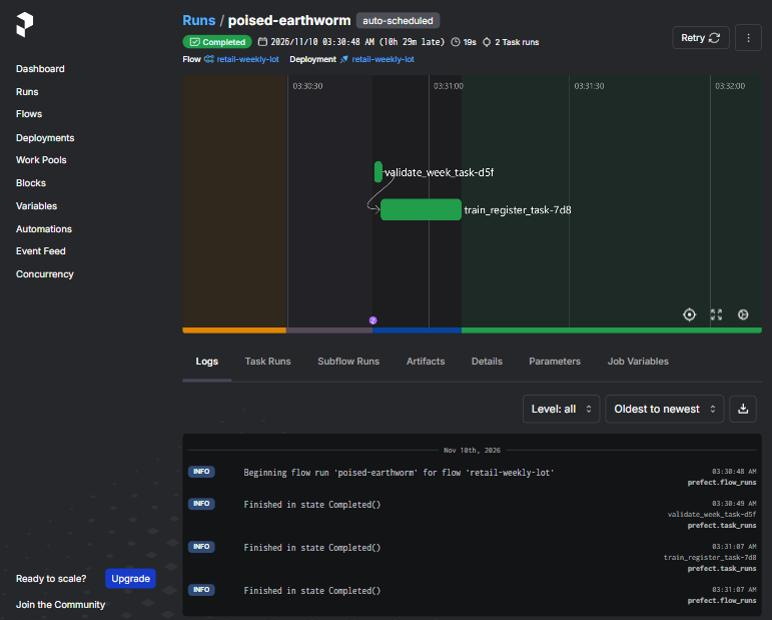

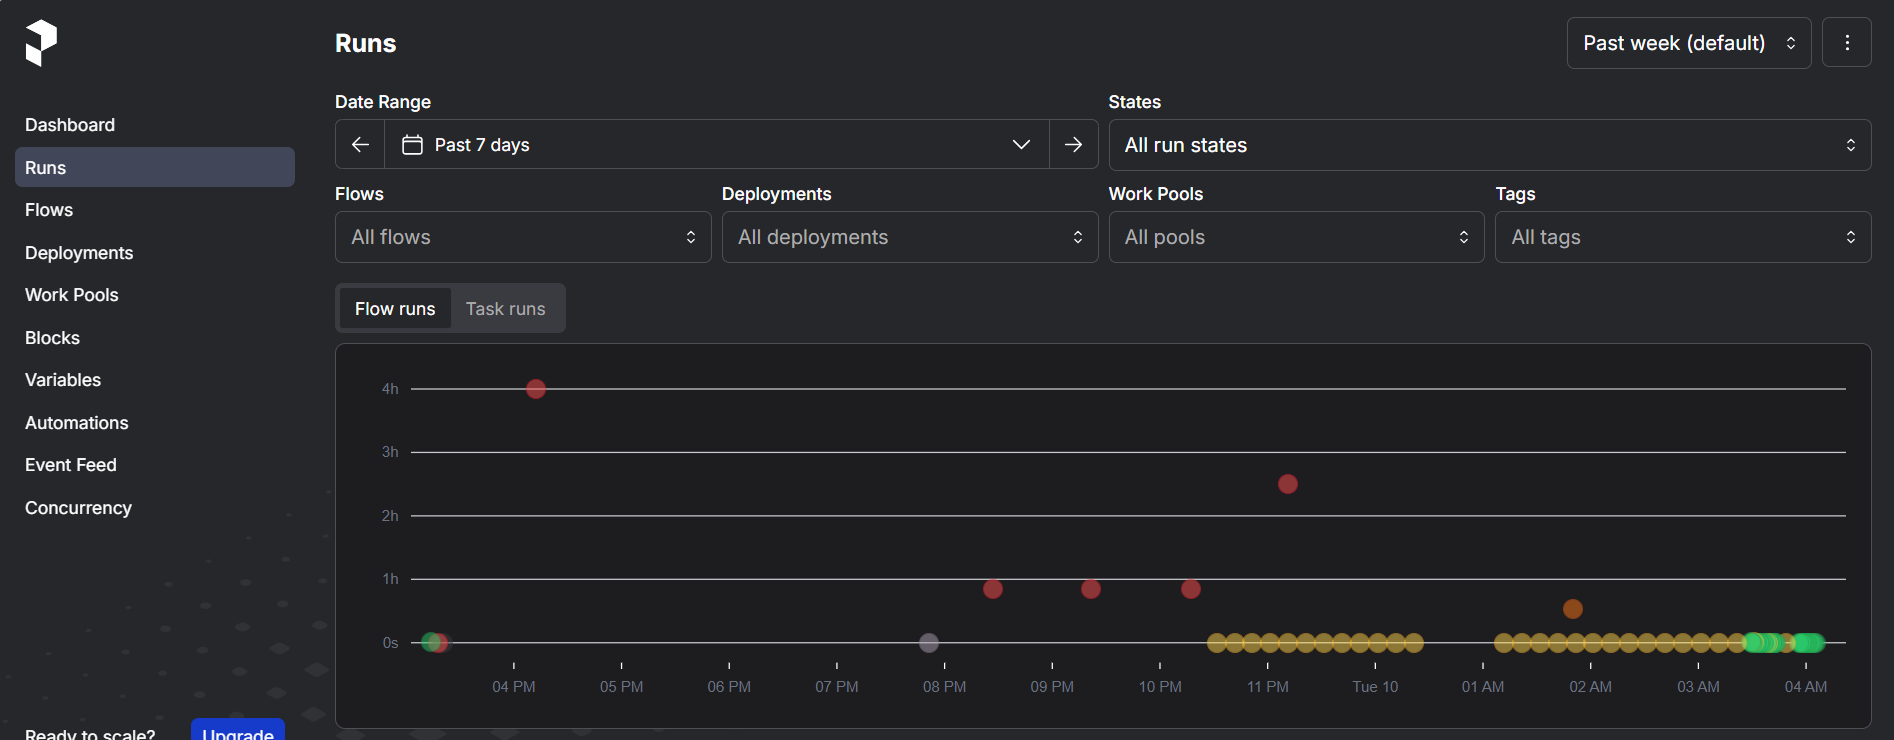

### 4. Traçabilité et modèles avec MLflow

#### 4.1 Découpage temporel et pipeline du modèle

Les dernières semaines servent de jeu de test et ne sont jamais mélangées à l'entraînement. Le découpage vérifie explicitement l'absence de fuite temporelle. Le modèle est un pipeline scikit-learn : normalisation des variables numériques, encodage du produit, puis régression Ridge.

In [ ]:
# Fichier : src/retail/training/train.py (lignes 37 à 52)
def temporal_split(frame: pd.DataFrame, test_weeks: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    weeks = ordered_weeks(frame["iso_week"].unique().tolist())
    if len(weeks) <= test_weeks:
        raise TrainError(
            f"Pas assez de semaines d'origine ({len(weeks)}) pour test_weeks={test_weeks}."
        )
    holdout = set(weeks[-test_weeks:])
    train = frame.loc[~frame["iso_week"].isin(holdout)].copy()
    test = frame.loc[frame["iso_week"].isin(holdout)].copy()
    if train.empty or test.empty:
        raise TrainError("Split temporel vide : réduire test_weeks ou warmup_weeks.")
    if max(ordered_weeks(train["iso_week"].unique().tolist())) >= min(
        ordered_weeks(test["iso_week"].unique().tolist())
    ):
        raise TrainError("Fuite temporelle : le train chevauche le test.")
    return train, test


# Fichier : src/retail/training/train.py (lignes 55 à 67)
def make_pipeline() -> Pipeline:
    transform = ColumnTransformer(
        [
            ("num", StandardScaler(), NUMERIC_FEATURES),
            ("sku", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["StockCode"]),
        ]
    )
    return Pipeline(
        [
            ("prep", transform),
            ("model", Ridge(alpha=1.0)),
        ]
    )

In [ ]:
# Fichier : src/retail/training/metrics.py (lignes 6 à 7)
def mae(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean(np.abs(y_true - y_pred)))


# Fichier : src/retail/training/metrics.py (lignes 10 à 14)
def wape(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    denom = float(np.abs(y_true).sum())
    if denom == 0:
        return 0.0
    return float(np.abs(y_true - y_pred).sum() / denom)

#### 4.2 Suivi des données, paramètres, métriques et artefacts

Chaque entraînement crée un run MLflow. Il enregistre les paramètres, les métriques du modèle et de la baseline naïve, des tags de traçabilité (empreinte des données, empreinte des variables, semaines d'entraînement et de test, commit Git) et les artefacts (modèle avec signature, liste des produits, fichier de métriques).

In [ ]:
# Fichier : src/retail/training/train.py (lignes 162 à 206), extrait de train_and_evaluate
mlflow.set_tracking_uri(tracking_uri())
mlflow.set_experiment(app.project.name)
with mlflow.start_run() as run:
    mlflow.log_params(
        {
            "algorithm": "ridge",
            "alpha": 1.0,
            "top_n": app.panel.top_n_products,
            "warmup_weeks": app.panel.warmup_weeks,
            "test_weeks": app.training.test_weeks,
            "lags": ",".join(str(x) for x in app.training.lags),
            "until_week": until_week or "",
        }
    )
    mlflow.log_metrics(
        {
            "mae_model": metrics["mae_model"],
            "wape_model": metrics["wape_model"],
            "mae_naive": metrics["mae_naive"],
            "wape_naive": metrics["wape_naive"],
        }
    )
    mlflow.set_tags(
        {
            "features_hash": metrics["features_hash"],
            "beats_baseline": str(metrics["beats_baseline"]).lower(),
            "train_weeks": ",".join(metrics["train_weeks"]),
            "test_weeks": ",".join(metrics["test_weeks"]),
            **({"data_hash": metrics["data_hash"]} if metrics["data_hash"] else {}),
            **({"git_commit": metrics["git_commit"]} if metrics["git_commit"] else {}),
        }
    )
    top_skus_path = app.paths.interim_dir / TOP_SKUS_FILENAME
    if top_skus_path.is_file():
        mlflow.log_artifact(str(top_skus_path))
    mlflow.log_artifact(str(metrics_path))
    signature = infer_signature(example, pipe.predict(example))
    mlflow.sklearn.log_model(
        pipe,
        artifact_path="model",
        signature=signature,
        input_example=example,
        pip_requirements=["scikit-learn"],
    )
    metrics["mlflow_run_id"] = run.info.run_id

#### 4.3 Versionnement, alias et règle de mise en service

Un run n'est enregistré dans le registre que s'il bat la baseline naïve. Il reçoit alors l'alias `challenger` et ses tags. Il devient `champion` si sa MAE est inférieure ou égale à celle du champion, **calculée sur les mêmes semaines de test**. La décision est écrite en tag sur la version.

In [ ]:
# Fichier : src/retail/registry/promote.py (lignes 426 à 461)
def register_run(
    app: AppConfig,
    metrics: dict,
    *,
    x_test: pd.DataFrame | None = None,
    y_test: np.ndarray | None = None,
) -> dict:
    """Enregistre le run en challenger s'il bat le naïf ; promeut si MAE ≤ champion (même test)."""
    if app.promotion.must_beat_baseline and not metrics.get("beats_baseline"):
        log.info("Run non enregistré : n'a pas battu la baseline naïve")
        return {"status": "skipped", "reason": "baseline"}
    run_id = metrics.get("mlflow_run_id")
    if not run_id:
        raise RegistryError("mlflow_run_id manquant : relancer `retail train`.")

    client = _client()
    name = _model_name(app)
    _ensure_registered_model(client, name)
    mv = mlflow.register_model(f"runs:/{run_id}/model", name)
    version = str(mv.version)
    client.set_registered_model_alias(name, CHALLENGER_ALIAS, version)
    _set_tags(
        client,
        name,
        version,
        {
            "data_hash": metrics.get("data_hash"),
            "features_hash": metrics.get("features_hash"),
            "until_week": metrics.get("until_week"),
            "beats_baseline": metrics.get("beats_baseline"),
            "run_id": run_id,
            TAG_PIPELINE: STATUS_IN_PROGRESS,
        },
    )
    result: dict = {"status": "challenger", "model_version": version, "run_id": run_id}
    return _finish_versus_champion(app, client, name, version, run_id, x_test, y_test, result)


# Fichier : src/retail/registry/promote.py (lignes 464 à 527)
def _finish_versus_champion(
    app: AppConfig,
    client: MlflowClient,
    name: str,
    version: str,
    run_id: str,
    x_test: pd.DataFrame | None,
    y_test: np.ndarray | None,
    result: dict | None = None,
) -> dict:
    result = result or {"status": "challenger", "model_version": version, "run_id": run_id}
    champ = _alias_version(client, name, CHAMPION_ALIAS)
    if champ is None:
        _promote(client, app, name, version, previous=None)
        decision = "promoted: first champion"
        _set_tags(client, name, version, {TAG_DECISION: decision, TAG_PIPELINE: STATUS_COMPLETE})
        result.update({"status": "champion", "promoted": True, "decision": decision})
        log.info("Premier champion", extra={"version": version})
        return result

    if x_test is None or y_test is None:
        raise RegistryError(
            "Jeu de test requis pour comparer le champion et le challenger sur les mêmes semaines."
        )
    new_scores = _score(f"runs:/{run_id}/model", x_test, y_test)
    result["mae_challenger_same_test"] = new_scores["mae"]
    result["wape_challenger_same_test"] = new_scores["wape"]
    result["champion_version"] = champ
    champ_uri = f"models:/{name}/{champ}"
    compatible = _champion_schema_compatible(champ_uri, x_test)
    if compatible is False:
        return _promote_incompatible(
            client, app, name, version, champ, result, INCOMPATIBLE_DECISION
        )
    if compatible is None:
        try:
            champ_scores = _score(champ_uri, x_test, y_test)
        except (ValueError, KeyError, MlflowException):
            return _promote_incompatible(
                client, app, name, version, champ, result, NO_SIGNATURE_DECISION
            )
    else:
        champ_scores = _score(champ_uri, x_test, y_test)
    result["mae_champion_same_test"] = champ_scores["mae"]

    if new_scores["mae"] <= champ_scores["mae"]:
        _promote(client, app, name, version, previous=champ)
        decision = (
            f"promoted: mae {new_scores['mae']:.4f} <= champion {champ} "
            f"mae {champ_scores['mae']:.4f} on same test"
        )
        _set_tags(client, name, version, {TAG_DECISION: decision, TAG_PIPELINE: STATUS_COMPLETE})
        result.update({"status": "champion", "promoted": True, "decision": decision})
        log.info("Champion promu", extra={"version": version, "previous": champ})
        return result

    decision = (
        f"challenger: mae {new_scores['mae']:.4f} > champion {champ} "
        f"mae {champ_scores['mae']:.4f} on same test"
    )
    _set_tags(client, name, version, {TAG_DECISION: decision, TAG_PIPELINE: STATUS_COMPLETE})
    result.update({"promoted": False, "decision": decision})
    log.info("Reste challenger", extra={"version": version, "champion": champ})
    return result

#### 4.4 Retour à une version précédente

Le retour arrière ré-aliase la version précédente, retrouvée grâce au tag `previous_champion`, ou une version choisie avec `--to-version`. Le champion est aussi exporté sur disque (`models/champion/`) pour servir de repli si MLflow tombe.

In [ ]:
# Fichier : src/retail/registry/promote.py (lignes 530 à 553)
def rollback_champion(app: AppConfig, to_version: str | None = None) -> dict:
    """Ré-alias une version précédente (tag MLflow ``previous_champion`` ou ``--to-version``)."""
    client = _client()
    name = _model_name(app)
    current = _alias_version(client, name, CHAMPION_ALIAS)
    if current is None:
        raise RegistryError("Aucun champion : rien à restaurer.")
    if to_version:
        target = str(to_version)
        try:
            client.get_model_version(name, target)
        except MlflowException as exc:
            raise RegistryError(f"Version {target} introuvable dans le registre.") from exc
    else:
        target = _version_tag(client, name, current, TAG_PREVIOUS)
        if not target:
            raise RegistryError("Pas de version précédente (premier champion).")
    if target == current:
        raise RegistryError(f"Le champion est déjà la version {current}.")

    export_version(app, target)
    client.set_registered_model_alias(name, CHAMPION_ALIAS, target)
    log.info("Rollback champion", extra={"from": current, "to": target})
    return {"status": "rolled_back", "model_version": target, "replaced": current}

**Interprétation :**

Ces cellules nécessitent le serveur MLflow et ne sont pas exécutées ici. La capture du registre `retail-weekly-qty` ci-dessous montre le résultat réel : la version 7 porte les alias `champion` et `challenger`, les tags `data_hash`, `features_hash`, `until_week: 2011-W48`, `beats_baseline: True`, `run_id`, `pipeline_status: complete`, `previous_champion: 6`, et la décision « promoted: mae 242.9378 <= champion … » (texte tronqué dans l'interface). Le retour arrière de la version 7 vers la version 6 est démontré à l'étape 4 de la démonstration (partie 9).

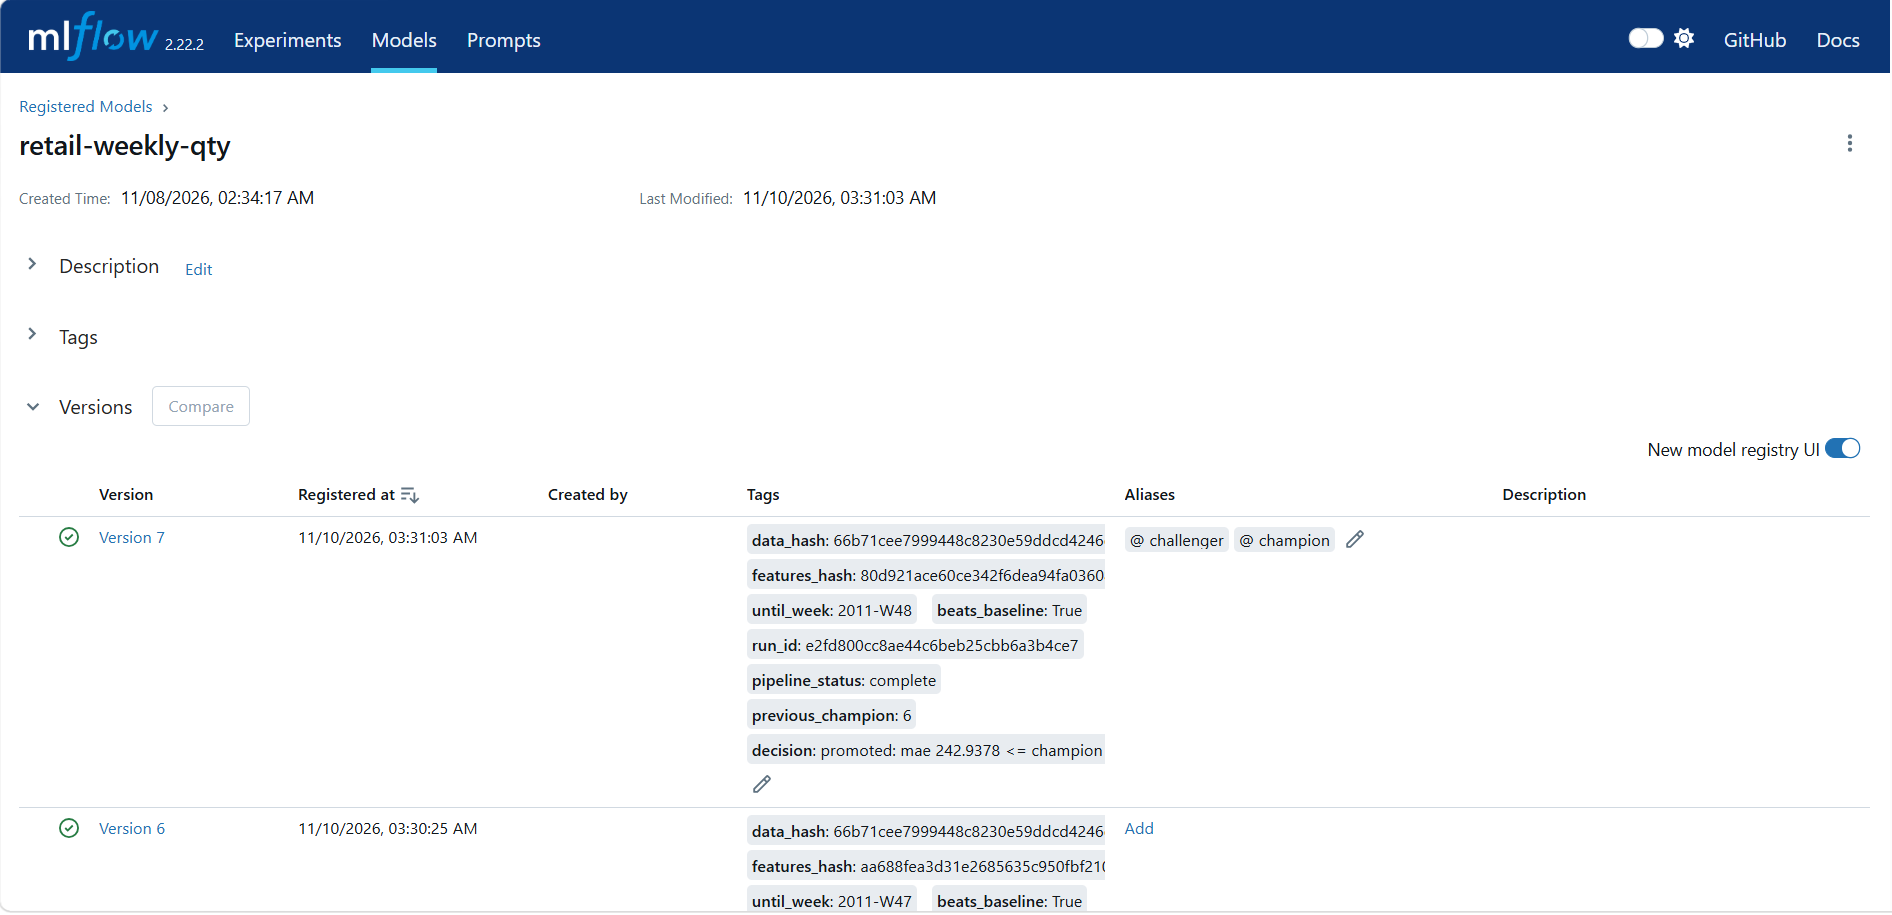

### 5. API de prédiction FastAPI

#### 5.1 Validation des entrées

Les requêtes sont décrites par des modèles Pydantic. Une semaine doit respecter le format `AAAA-Www` **et** exister dans le calendrier ISO. Les champs inconnus sont refusés (`extra="forbid"`), et les quantités de feedback doivent être positives ou nulles.

In [ ]:
# Fichier : src/retail/api/schemas.py (lignes 9 à 27)
ISO_WEEK = r"^\d{4}-W\d{2}$"


def _calendar_iso_week(week: str) -> str:
    year_s, week_s = week.split("-W", 1)
    date.fromisocalendar(int(year_s), int(week_s), 1)
    return week


IsoWeek = Annotated[str, Field(pattern=ISO_WEEK), AfterValidator(_calendar_iso_week)]


class PredictRequest(BaseModel):
    """Prédiction métier : le serveur calcule les lags depuis le panel."""

    model_config = ConfigDict(extra="forbid")

    StockCode: str = Field(min_length=1)
    week: IsoWeek

In [ ]:
# Fichier : src/retail/api/schemas.py (lignes 69 à 75)
class FeedbackRequest(BaseModel):
    StockCode: str = Field(min_length=1)
    iso_week: IsoWeek
    actual_qty: float = Field(ge=0)
    predicted_qty: float | None = Field(default=None, ge=0)
    model_version: str | None = None
    prediction_id: UUID

In [11]:
from pydantic import ValidationError

from retail.api.schemas import FeedbackRequest, PredictRequest

print("Valide :", PredictRequest(StockCode="85123A", week="2011-W41"))
essais = [
    {"StockCode": "85123A", "week": "2011-41"},
    {"StockCode": "85123A", "week": "2011-W60"},
    {"StockCode": "", "week": "2011-W41"},
    {"StockCode": "85123A", "week": "2011-W41", "prix": 3},
]
for body in essais:
    try:
        PredictRequest(**body)
    except ValidationError as exc:
        err = exc.errors()[0]
        print(f"Refusé {body} -> {err['type']} : {err['msg']}")

Valide : StockCode='85123A' week='2011-W41'
Refusé {'StockCode': '85123A', 'week': '2011-41'} -> string_pattern_mismatch : String should match pattern '^\d{4}-W\d{2}$'
Refusé {'StockCode': '85123A', 'week': '2011-W60'} -> value_error : Value error, Invalid week: 60
Refusé {'StockCode': '', 'week': '2011-W41'} -> string_too_short : String should have at least 1 character
Refusé {'StockCode': '85123A', 'week': '2011-W41', 'prix': 3} -> extra_forbidden : Extra inputs are not permitted


**Interprétation :**

Seule la première requête est acceptée. Les quatre autres sont refusées avant d'atteindre le modèle : format de semaine incorrect, semaine 60 inexistante dans le calendrier ISO, code produit vide et champ inconnu. Dans l'API, ces refus deviennent des réponses HTTP 422, et ils sont aussi tracés en base avec le statut `error`.

#### 5.2 Prédiction en ligne et par lot, erreurs et version

`/predict` prédit pour un produit et une semaine ; les variables de retard sont calculées côté serveur à partir du panel. `/predict/batch` prédit les 50 produits d'une semaine et les enregistre en une seule insertion. Un produit inconnu donne une erreur 404, une semaine hors horizon une erreur 422, un modèle absent une erreur 503. Chaque réponse contient `model_version`, `source` et un `prediction_id`.

In [ ]:
# Fichier : src/retail/api/app.py (lignes 383 à 406)
@api.post("/predict", response_model=PredictResponse)
def predict(item: PredictRequest, request: Request) -> PredictResponse:
    started = time.perf_counter()
    _require_store()
    if store.skus and item.StockCode not in store.skus:
        raise HTTPException(status_code=404, detail=f"SKU inconnu : {item.StockCode}")
    try:
        frame = feature_row(
            app_cfg,
            item.StockCode,
            item.week,
            sorted(store.skus),
            model_version=store.model_version,
        )
    except FeatureLookupError as exc:
        raise HTTPException(status_code=422, detail=str(exc)) from exc
    value = store.predict_frame(frame)[0]
    return _reply(
        item.StockCode,
        value,
        week=item.week,
        latency_ms=(time.perf_counter() - started) * 1000,
        request=request,
    )


# Fichier : src/retail/api/app.py (lignes 408 à 449)
@api.post("/predict/batch", response_model=BatchPredictResponse)
def predict_batch(body: BatchPredictRequest, request: Request) -> BatchPredictResponse:
    started = time.perf_counter()
    _require_store()
    skus = sorted(store.skus)
    if not skus:
        raise HTTPException(status_code=503, detail="Liste de produits du champion absente")
    try:
        rows = features_for_week(app_cfg, body.week, skus, model_version=store.model_version)
    except FeatureLookupError as exc:
        raise HTTPException(status_code=422, detail=str(exc)) from exc
    preds = store.predict_frame(rows[FEATURE_COLUMNS])
    latency_ms = (time.perf_counter() - started) * 1000
    items: list[PredictResponse] = []
    traces: list[dict] = []
    for code, value in zip(rows["StockCode"].tolist(), preds, strict=True):
        reply = _reply(
            str(code),
            value,
            week=body.week,
            latency_ms=latency_ms,
            persist=False,
            request=request,
        )
        items.append(reply)
        traces.append(
            _trace(
                str(code),
                value,
                body.week,
                latency_ms=latency_ms,
                prediction_id=reply.prediction_id,
                request=request,
            )
        )
    persist_predictions(traces)
    return BatchPredictResponse(
        predictions=items,
        model_version=store.model_version,
        source=store.source,
        week=body.week,
    )

Un middleware ajoute l'en-tête `X-Model-Version` à toutes les réponses et alimente les métriques Prometheus de volume et de latence.

In [ ]:
# Fichier : src/retail/api/app.py (lignes 184 à 202)
@api.middleware("http")
async def _http_metrics(request: Request, call_next):
    if request.url.path in {"/metrics", "/health/live"}:
        return await call_next(request)
    started = time.perf_counter()
    method = request.method
    try:
        response = await call_next(request)
    except Exception:
        path = _metric_path(request)
        http_count.labels(method, path, "500").inc()
        http_latency.labels(method, path).observe(time.perf_counter() - started)
        raise
    path = _metric_path(request)
    status = str(response.status_code)
    http_count.labels(method, path, status).inc()
    http_latency.labels(method, path).observe(time.perf_counter() - started)
    response.headers["X-Model-Version"] = store.model_version
    return response

Le modèle servi est chargé depuis l'alias `champion` de MLflow. Si MLflow est indisponible, l'API se replie sur le champion exporté sur disque, puis sur une sauvegarde, et signale ce **mode dégradé** dans `/health`.

In [ ]:
# Fichier : src/retail/api/store.py (lignes 191 à 230)
def _load_fresh(self) -> ServingState:
    if skip_registry_probe():
        dest = self._champion_dir()
        bak = dest.parent / ".champion.bak"
        if self._dir_ready(dest):
            return self._state_from_dir(dest, "disk", registry_ok=True)
        if self._dir_ready(bak):
            return self._state_from_dir(bak, "bak", registry_ok=False)
        raise ModelNotReadyError("Aucun champion local (models/champion/ ni .champion.bak).")
    name = self.app.promotion.registered_model_name
    uri = tracking_uri()
    mlflow.set_tracking_uri(uri)
    try:
        client = MlflowClient(tracking_uri=uri)
        mv = client.get_model_version_by_alias(name, CHAMPION_ALIAS)
        version = str(mv.version)
        pipeline = mlflow.sklearn.load_model(f"models:/{name}/{version}")
        skus = load_run_skus(mv.run_id)
        log.info("Modèle chargé depuis MLflow", extra={"version": version})
        return ServingState(
            pipeline=pipeline,
            skus=frozenset(skus),
            model_version=version,
            source="mlflow",
            meta={
                "registered_model": name,
                "model_version": version,
                "run_id": mv.run_id,
            },
            registry_ok=True,
        )
    except (MlflowException, OSError, FileNotFoundError) as exc:
        log.warning("MLflow indisponible, repli disque", extra={"error": str(exc)})
    dest = self._champion_dir()
    bak = dest.parent / ".champion.bak"
    if self._dir_ready(dest):
        return self._state_from_dir(dest, "disk", registry_ok=False)
    if self._dir_ready(bak):
        return self._state_from_dir(bak, "bak", registry_ok=False)
    raise ModelNotReadyError("Aucun champion local (models/champion/ ni .champion.bak).")

**Interprétation :**

Ces cellules demandent un modèle entraîné et ne sont pas exécutées ici. Le journal de la démonstration (`docs/captures/demo.txt`) montre leur fonctionnement réel : `/health` répond `status=ok`, `model_version=7`, `db_backend=postgresql`, et `/predict/batch` sur 2011-W41 renvoie 50 prédictions avec `model_version=7 source=mlflow`.

### 6. Retours et persistance des traces

#### 6.1 Tables de traces

Quatre tables SQLAlchemy conservent les traces d'utilisation : chaque prédiction avec sa version, sa source, sa latence, son statut et son erreur éventuelle ; les feedbacks ; les exécutions du pipeline ; les alertes.

In [ ]:
# Fichier : src/retail/db/models.py (lignes 1 à 66)
from __future__ import annotations

from datetime import datetime

from sqlalchemy import Boolean, DateTime, Float, Integer, String, Text
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column
from sqlalchemy.types import JSON


class Base(DeclarativeBase):
    pass


class Prediction(Base):
    __tablename__ = "predictions"

    prediction_id: Mapped[str] = mapped_column(String(36), primary_key=True)
    created_at: Mapped[datetime] = mapped_column(DateTime(timezone=True), nullable=False)
    iso_week: Mapped[str | None] = mapped_column(String(10), index=True)
    stock_code: Mapped[str] = mapped_column(String(64), nullable=False, index=True)
    predicted_qty: Mapped[float] = mapped_column(Float, nullable=False)
    model_version: Mapped[str] = mapped_column(String(32), nullable=False, index=True)
    source: Mapped[str] = mapped_column(String(16), nullable=False)
    latency_ms: Mapped[float | None] = mapped_column(Float)
    status: Mapped[str] = mapped_column(String(16), nullable=False, default="ok")
    error: Mapped[str | None] = mapped_column(Text)


class Feedback(Base):
    __tablename__ = "feedbacks"

    id: Mapped[int] = mapped_column(Integer, primary_key=True, autoincrement=True)
    prediction_id: Mapped[str | None] = mapped_column(String(36), index=True)
    stock_code: Mapped[str] = mapped_column(String(64), nullable=False)
    iso_week: Mapped[str] = mapped_column(String(10), nullable=False, index=True)
    actual_qty: Mapped[float] = mapped_column(Float, nullable=False)
    predicted_qty: Mapped[float | None] = mapped_column(Float)
    abs_error: Mapped[float | None] = mapped_column(Float)
    model_version: Mapped[str | None] = mapped_column(String(32), index=True)
    origin: Mapped[str] = mapped_column(String(16), nullable=False)
    created_at: Mapped[datetime] = mapped_column(DateTime(timezone=True), nullable=False)


class PipelineRun(Base):
    __tablename__ = "pipeline_runs"

    id: Mapped[int] = mapped_column(Integer, primary_key=True, autoincrement=True)
    iso_week: Mapped[str] = mapped_column(String(10), nullable=False, index=True)
    status: Mapped[str] = mapped_column(String(32), nullable=False)
    duration_s: Mapped[float | None] = mapped_column(Float)
    model_version: Mapped[str | None] = mapped_column(String(32))
    error: Mapped[str | None] = mapped_column(Text)
    trained: Mapped[bool | None] = mapped_column(Boolean)
    created_at: Mapped[datetime] = mapped_column(DateTime(timezone=True), nullable=False)


class Alert(Base):
    __tablename__ = "alerts"

    id: Mapped[int] = mapped_column(Integer, primary_key=True, autoincrement=True)
    kind: Mapped[str] = mapped_column(String(64), nullable=False)
    iso_week: Mapped[str | None] = mapped_column(String(10), index=True)
    message: Mapped[str] = mapped_column(Text, nullable=False)
    origin: Mapped[str] = mapped_column(String(16), nullable=False)
    created_at: Mapped[datetime] = mapped_column(DateTime(timezone=True), nullable=False)
    payload: Mapped[dict | None] = mapped_column(JSON)

In [12]:
from sqlalchemy import create_engine, inspect

from retail.db.models import Base

engine = create_engine("sqlite:///:memory:")
Base.metadata.create_all(engine)
inspector = inspect(engine)
for table in inspector.get_table_names():
    print(f"{table:<14}", ", ".join(col["name"] for col in inspector.get_columns(table)))

alerts         id, kind, iso_week, message, origin, created_at, payload
feedbacks      id, prediction_id, stock_code, iso_week, actual_qty, predicted_qty, abs_error, model_version, origin, created_at
pipeline_runs  id, iso_week, status, duration_s, model_version, error, trained, created_at
predictions    prediction_id, created_at, iso_week, stock_code, predicted_qty, model_version, source, latency_ms, status, error


**Interprétation :**

Le schéma est créé ici dans une base SQLite en mémoire, sans toucher à PostgreSQL. Les colonnes demandées par le sujet sont présentes : prédiction, version associée (`model_version`), durée (`latency_ms`, `duration_s`) et erreur (`status`, `error`). En démonstration, les mêmes tables sont créées dans PostgreSQL par `retail db-init`.

#### 6.2 Écriture non bloquante

Les écritures passent par une file bornée et un écrivain en arrière plan. Si la base est lente ou coupée, l'API continue de répondre et compte les écritures abandonnées dans `retail_db_dropped_total`.

In [ ]:
# Fichier : src/retail/db/repo.py (lignes 199 à 211)
def enqueue(kind: str, row: dict[str, Any]) -> None:
    if get_settings().database_sync:
        try:
            _flush_batch([(kind, row)])
        except Exception as exc:
            _record_drop(_item_weight(kind, row))
            log.warning("Persistance ignorée (l'API continue)", extra={"error": str(exc)})
        return
    _ensure_worker()
    try:
        _queue.put_nowait((kind, row))
    except queue.Full:
        _record_drop(_item_weight(kind, row))

#### 6.3 Collecte des feedbacks

Les feedbacks arrivent de deux façons. Un client peut appeler `POST /feedback` avec un `prediction_id`. Surtout, quand le lot d'une semaine est validé, ses ventes réelles ferment automatiquement les prédictions faites pour cette semaine (`origin = auto`). La WAPE de production par version en découle. Le trafic des tests de charge, marqué par l'en-tête `X-Load-Test`, est exclu.

In [ ]:
# Fichier : src/retail/api/app.py (lignes 467 à 493)
@api.post("/feedback", status_code=202)
def feedback(body: FeedbackRequest) -> dict:
    _require_store()
    if store.skus and body.StockCode not in store.skus:
        raise HTTPException(status_code=404, detail=f"SKU inconnu : {body.StockCode}")
    pred = get_prediction(str(body.prediction_id))
    if pred is None:
        raise HTTPException(
            status_code=404,
            detail=f"Prédiction introuvable : {body.prediction_id}",
        )
    path = app_cfg.paths.reports_dir / "feedback.jsonl"
    payload = body.model_dump(mode="json")
    payload["received_at"] = datetime.now(UTC).isoformat(timespec="seconds")
    append_jsonl(path, payload)
    persist_feedback(
        {
            "prediction_id": str(body.prediction_id),
            "stock_code": body.StockCode,
            "iso_week": body.iso_week,
            "actual_qty": body.actual_qty,
            "predicted_qty": pred["predicted_qty"],
            "model_version": pred["model_version"] or store.model_version,
            "origin": "http",
        }
    )
    return {"status": "accepted"}

In [ ]:
# Fichier : src/retail/db/auto_feedback.py (lignes 22 à 82)
def auto_feedback_for_week(app: AppConfig, week: str) -> dict:
    """Quand le lot ``week`` est validé, ses quantités ferment les prédictions de cette semaine."""
    panel_path = Path(app.paths.interim_dir) / "panel" / f"{week}.parquet"
    if not panel_path.is_file():
        return {"week": week, "matched": 0, "wape": None}
    try:
        ensure_schema()
        panel = pd.read_parquet(panel_path, engine="pyarrow", memory_map=False)
        actuals = {
            str(code): float(qty)
            for code, qty in zip(
                panel["StockCode"].astype(str), panel["quantity"].astype(float), strict=True
            )
        }
        unmatched = ~exists(
            select(Feedback.id).where(Feedback.prediction_id == Prediction.prediction_id)
        )
        with session_scope() as session:
            preds = session.scalars(
                select(Prediction).where(
                    Prediction.iso_week == week,
                    Prediction.status == "ok",
                    Prediction.source != LOADTEST_SOURCE,
                    unmatched,
                )
            ).all()
            now = datetime.now(UTC)
            rows: list[dict] = []
            actual_list: list[float] = []
            pred_list: list[float] = []
            for pred in preds:
                actual = actuals.get(pred.stock_code, 0.0)
                rows.append(
                    {
                        "prediction_id": pred.prediction_id,
                        "stock_code": pred.stock_code,
                        "iso_week": week,
                        "actual_qty": actual,
                        "predicted_qty": pred.predicted_qty,
                        "abs_error": abs(actual - pred.predicted_qty),
                        "model_version": pred.model_version,
                        "origin": "auto",
                        "created_at": now,
                    }
                )
                actual_list.append(actual)
                pred_list.append(pred.predicted_qty)
            if rows:
                session.execute(insert(Feedback), rows)
            matched = len(rows)
        score = None
        if actual_list:
            score = wape(np.array(actual_list, dtype=float), np.array(pred_list, dtype=float))
        log.info(
            "Feedback automatique",
            extra={"week": week, "matched": matched, "wape": score},
        )
        return {"week": week, "matched": matched, "wape": score}
    except Exception as exc:
        log.warning("Feedback automatique ignoré (base indisponible)", extra={"error": str(exc)})
        return {"week": week, "matched": 0, "wape": None, "error": str(exc)}

**Interprétation :**

Ces fonctions exigent PostgreSQL et ne sont pas exécutées ici. Dans la démonstration, le rejeu de 2011-W41 a fermé 50 prédictions (`matched: 50`) et `GET /model` a renvoyé une WAPE de production de 0,7047 pour la version 7. La boucle est donc complète : prédiction tracée, vérité terrain reçue, erreur mesurée par version.

### 7. Tests de charge et dimensionnement

#### 7.1 Protocole Locust

Le trafic mélange 70 % de prédictions unitaires, 20 % de prédictions par lot et 10 % de sondes de santé. La charge monte par paliers de 2 à 320 utilisateurs, chaque palier durant 45 secondes. Les requêtes portent l'en-tête `X-Load-Test` pour être exclues des métriques métier.

In [ ]:
# Fichier : load_tests/locustfile.py (lignes 21 à 23)
DEFAULT_WEEK = "2011-W48"
USER_LEVELS = (2, 5, 10, 20, 40, 80, 160, 320)
STAGE_SECONDS = int(os.environ.get("LOCUST_STAGE_SECONDS", "45"))

In [ ]:
# Fichier : load_tests/locustfile.py (lignes 49 à 64)
def load_shape_stages() -> tuple[dict, ...]:
    if os.environ.get("LOCUST_SMOKE", "").strip() in {"1", "true", "yes"}:
        return ({"duration": 30, "users": 5, "spawn_rate": 5.0, "label": "smoke"},)
    elapsed = 0
    stages: list[dict] = []
    for users in USER_LEVELS:
        elapsed += STAGE_SECONDS
        stages.append(
            {
                "duration": elapsed,
                "users": users,
                "spawn_rate": float(max(users / 5.0, 2.0)),
                "label": f"u{users}",
            }
        )
    return tuple(stages)


# Fichier : load_tests/locustfile.py (lignes 72 à 124)
class RetailUser(HttpUser):
    # Capacité : pause courte pour saturer ; continu : ~1 req/s par user, bien sous la capacité.
    wait_time = between(0.5, 1.5) if CONSTANT_MODE else between(0.05, 0.2)

    def on_start(self) -> None:
        global _skus
        if _skus:
            return
        with _skus_lock:
            if _skus:
                return
            fetched: list[str] = []
            try:
                url = f"{self.host.rstrip('/')}/model"
                with urllib.request.urlopen(url, timeout=5) as response:
                    payload = json.loads(response.read().decode("utf-8"))
                fetched = [str(item) for item in payload.get("skus") or [] if str(item).strip()]
            except (OSError, TimeoutError, json.JSONDecodeError, ValueError):
                fetched = []
            _skus = fetched or load_skus_from_disk()

    def _sku(self) -> str:
        pool = _skus or load_skus_from_disk()
        return random.choice(pool)

    @task(70)
    def predict_one(self) -> None:
        self.client.post(
            "/predict",
            json={"StockCode": self._sku(), "week": WEEK},
            name="/predict",
            timeout=REQUEST_TIMEOUT_S,
            headers=LOAD_HEADERS,
        )

    @task(20)
    def predict_batch(self) -> None:
        self.client.post(
            "/predict/batch",
            json={"week": WEEK},
            name="/predict/batch",
            timeout=REQUEST_TIMEOUT_S,
            headers=LOAD_HEADERS,
        )

    @task(10)
    def health(self) -> None:
        self.client.get(
            "/health/live",
            name="/health/live",
            timeout=REQUEST_TIMEOUT_S,
            headers=LOAD_HEADERS,
        )

Le même protocole est appliqué à trois configurations de l'API Docker, limitées en CPU et en mémoire. La capacité retenue est le dernier palier dont le p95 reste sous 200 ms sans erreur.

In [ ]:
# Fichier : load_tests/run.py (lignes 20 à 27)
P95_LIMIT_MS = 200.0
USER_LEVELS = (2, 5, 10, 20, 40, 80, 160, 320)

CONFIGS = (
    {"name": "1w_0p5cpu", "workers": "1", "cpus": "0.50", "mem": "1g"},
    {"name": "2w_1cpu", "workers": "2", "cpus": "1.00", "mem": "1g"},
    {"name": "4w_2cpu", "workers": "4", "cpus": "2.00", "mem": "2g"},
)

In [ ]:
# Fichier : load_tests/run.py (lignes 311 à 319)
def pick_capacity(windows: list[tuple[str, float, float]], phases: dict) -> dict | None:
    """Dernier palier valide avant le premier échec (p95 ≥ 200 ms ou erreurs)."""
    capacity = None
    for label, _, _ in windows:
        phase = phases.get(label)
        if not phase or phase["p95_ms"] >= P95_LIMIT_MS or phase["errors"] > 0:
            break
        capacity = {**phase, "label": label}
    return capacity

#### 7.2 Résultats mesurés

La campagne complète (`python load_tests/run.py`) a été lancée le 7 novembre 2026 et ses résultats sont dans `load_tests/results/summary.json`. La cellule suivante relit ce fichier ; elle ne relance aucun test.

In [13]:
summary = json.loads((ROOT / "load_tests" / "results" / "summary.json").read_text(encoding="utf-8"))
rows = []
for cfg in summary:
    for label, phase in cfg["phases"].items():
        rows.append({"config": cfg["name"], "users": int(phase["users"]),
                     "req/s": phase["rps"], "p95 (ms)": phase["p95_ms"], "erreurs": phase["errors"]})
phases = pd.DataFrame(rows)
print(phases.pivot(index="users", columns="config", values="req/s").to_string())
print()
print(phases.pivot(index="users", columns="config", values="p95 (ms)").to_string())
print()
cap = pd.DataFrame([{"config": c["name"], "workers": c["workers"], "vCPU": c["cpus"],
                     "palier": c["capacity"]["users"], "capacité (req/s)": c["capacity"]["rps"],
                     "p95 (ms)": c["capacity"]["p95_ms"], "source": c["health"]["source"]}
                    for c in summary])
print(cap.to_string(index=False))

config  1w_0p5cpu  2w_1cpu  4w_2cpu
users                              
2           12.44    12.89    12.27
5           29.80    31.00    31.33
10          32.42    55.78    60.18
20          29.33    49.87    81.62
40          23.42    40.04    77.00
80          21.73    33.33    80.76
160         22.33    33.49    68.36
320         21.47    34.69    58.00

config  1w_0p5cpu  2w_1cpu  4w_2cpu
users                              
2            51.0     27.0     34.0
5           120.0     49.0     49.0
10          310.0    110.0     60.0
20         1500.0    720.0    360.0
40         3800.0   1900.0   1200.0
80         6000.0   4100.0   2100.0
160        6800.0   9800.0   4900.0
320       17000.0  16000.0  11000.0

   config workers vCPU palier  capacité (req/s)  p95 (ms) source
1w_0p5cpu       1 0.50      5             29.80     120.0   disk
  2w_1cpu       2 1.00     10             55.78     110.0   disk
  4w_2cpu       4 2.00     10             60.18      60.0   disk


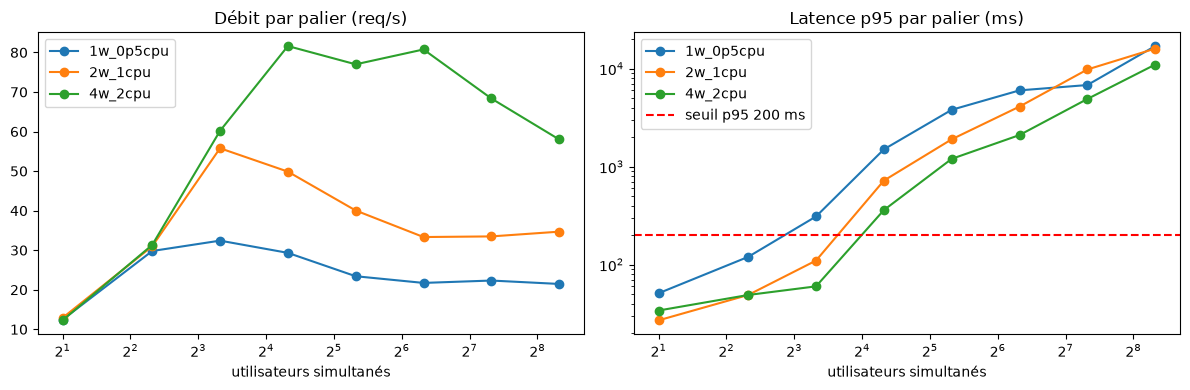

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, grp in phases.groupby("config"):
    grp = grp.sort_values("users")
    axes[0].plot(grp["users"], grp["req/s"], marker="o", label=name)
    axes[1].plot(grp["users"], grp["p95 (ms)"], marker="o", label=name)
axes[1].axhline(200, color="red", linestyle="--", label="seuil p95 200 ms")
for ax, title in zip(axes, ["Débit par palier (req/s)", "Latence p95 par palier (ms)"]):
    ax.set_xscale("log", base=2)
    ax.set_xlabel("utilisateurs simultanés")
    ax.set_title(title)
    ax.legend()
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

**Interprétation :**

Les trois configurations ont été servies sans erreur. Avec 1 worker et 0,5 vCPU, la capacité sous 200 ms est de 29,8 req/s (palier de 5 utilisateurs). Avec 2 workers et 1 vCPU, elle monte à 55,8 req/s avec un p95 de 110 ms (palier de 10 utilisateurs). Avec 4 workers et 2 vCPU, elle est d'au moins 60,2 req/s : le palier suivant atteint 81,6 req/s mais dépasse 200 ms, donc la capacité réelle se situe entre 60 et 82 req/s. Au delà de la saturation, le débit baisse et la latence explose par effet de file d'attente.

#### 7.3 Recommandation chiffrée

La synthèse `docs/SYNTHESE_OPS.md` retient l'unité **2 workers, 1 vCPU, 768 Mo à 1 Go** : c'est la meilleure capacité garantie par vCPU mesurée. En gardant 30 % de marge sous la capacité mesurée, une instance absorbe environ 39 req/s. La cellule suivante applique cette règle à partir de la capacité relue dans `summary.json`.

In [15]:
import math

unit = next(c for c in summary if c["name"] == "2w_1cpu")
per_instance = unit["capacity"]["rps"] * 0.7
print(f"Capacité mesurée 2w/1 vCPU : {unit['capacity']['rps']} req/s, avec 30 % de marge : {per_instance:.1f} req/s")
for peak in (30, 100, 200):
    print(f"Pointe de {peak:>3} req/s -> {math.ceil(peak / per_instance)} instance(s) de 2 workers / 1 vCPU")

Capacité mesurée 2w/1 vCPU : 55.78 req/s, avec 30 % de marge : 39.0 req/s
Pointe de  30 req/s -> 1 instance(s) de 2 workers / 1 vCPU
Pointe de 100 req/s -> 3 instance(s) de 2 workers / 1 vCPU
Pointe de 200 req/s -> 6 instance(s) de 2 workers / 1 vCPU


**Interprétation :**

Le calcul retrouve la règle de la synthèse : une instance pour 30 req/s, trois pour 100 req/s et six pour 200 req/s, derrière un répartiteur de charge. La synthèse documente aussi une première série avant optimisation : le débit maximal est passé de 9,5 à 32,4 req/s en 1 worker, de 19,5 à 55,8 en 2 workers et de 38,8 à 81,6 en 4 workers, après la mise en cache de la lecture du dossier panel. Les traces écrites en base sont passées d'environ 21 % à environ 100 % grâce à l'insertion par lot.

### 8. Supervision avec Prometheus et Grafana

#### 8.1 Métriques exposées par l'API

L'API expose sur `/metrics` le nombre de requêtes par route et par code, un histogramme de latence, la version servie, le mode dégradé, l'état de la base et le nombre d'écritures abandonnées.

In [ ]:
# Fichier : src/retail/api/app.py (lignes 101 à 133), extrait de create_app
http_count = Counter(
    "retail_http_requests_total",
    "Requêtes HTTP",
    ["method", "path", "status"],
    **metric_kw,
)
http_latency = Histogram(
    "retail_http_request_seconds",
    "Latence HTTP",
    ["method", "path"],
    buckets=LATENCY_BUCKETS,
    **metric_kw,
)
degraded_kw = {**metric_kw}
version_kw = {**metric_kw}
if multiprocess:
    degraded_kw["multiprocess_mode"] = "livemax"
    version_kw["multiprocess_mode"] = "liveall"
degraded_gauge = Gauge("retail_model_degraded", "1 si mode dégradé", **degraded_kw)
version_gauge = Gauge(
    "retail_model_version",
    "Version du champion servi (0 si inconnue)",
    ["model_version", "source"],
    **version_kw,
)
db_dropped = Counter(
    "retail_db_dropped_total",
    "Écritures SQL abandonnées (file pleine ou base injoignable trop lente)",
    **metric_kw,
)
db_ok_kw = {**metric_kw}
if multiprocess:
    db_ok_kw["multiprocess_mode"] = "livemin"

#### 8.2 Règles d'alerte

Prometheus évalue quatre règles : mode dégradé, taux de 5xx supérieur à 5 %, API injoignable et base de traces injoignable.

In [16]:
print((ROOT / "monitoring" / "alerts.yml").read_text(encoding="utf-8"))

groups:
  - name: retail
    rules:
      - alert: RetailDegraded
        expr: retail_model_degraded == 1
        for: 1m
        labels:
          severity: warning
        annotations:
          summary: Mode dégradé depuis plus d'une minute
          description: L'API sert le champion disque (MLflow injoignable ou repli).

      - alert: RetailHigh5xx
        expr: |
          (
            sum(rate(retail_http_requests_total{status=~"5..",path!~"/metrics|/health.*"}[5m]))
            /
            clamp_min(sum(rate(retail_http_requests_total{path!~"/metrics|/health.*"}[5m])), 1e-9)
          ) > 0.05
        for: 1m
        labels:
          severity: critical
        annotations:
          summary: Plus de 5 % de réponses 5xx
          description: Taux d'erreurs serveur au-dessus du seuil de démonstration.

      - alert: RetailApiDown
        expr: up{job="retail-api"} == 0
        for: 30s
        labels:
          severity: critical
        annotations:
          summary: A

#### 8.3 Dashboard Grafana provisionné

Le dashboard `retail-mlops` est versionné en JSON et provisionné automatiquement. La cellule suivante liste ses panneaux et leur source.

In [17]:
dash = json.loads((ROOT / "monitoring" / "grafana" / "dashboards" / "retail-mlops.json").read_text(encoding="utf-8"))
for panel in dash["panels"]:
    targets = panel.get("targets", [])
    kind = "SQL PostgreSQL" if any("rawSql" in t for t in targets) else "Prometheus"
    print(f"{panel['type']:<15}{kind:<16}{panel['title']}")

stat           Prometheus      Requêtes / s
stat           Prometheus      Latence p95 (objectif < 200 ms)
stat           Prometheus      Taux 5xx
stat           Prometheus      Mode dégradé
stat           Prometheus      Postgres OK
stat           Prometheus      Version servie
timeseries     Prometheus      Latence p50 / p95 / p99
timeseries     Prometheus      Postgres (retail_db_ok)
timeseries     Prometheus      Erreurs 4xx / 5xx
timeseries     Prometheus      Écritures SQL abandonnées (par minute)
state-timeline Prometheus      Alertes Prometheus (API, Postgres, mode dégradé)
table          SQL PostgreSQL  WAPE de production par version
barchart       SQL PostgreSQL  WAPE par semaine
table          SQL PostgreSQL  Exécutions du pipeline
table          SQL PostgreSQL  Alertes du pipeline (qualité, webhook)
table          SQL PostgreSQL  Volume prédictions / feedbacks


**Interprétation :**

Le dashboard couvre les quatre axes demandés par le sujet. Les traitements sont suivis par les tables des exécutions du pipeline et des alertes. L'utilisation du service est suivie par le débit et le volume de prédictions et de feedbacks. Les performances apparaissent dans les latences p50, p95 et p99 et dans la WAPE de production par version et par semaine. Les erreurs sont suivies par les taux 4xx et 5xx, l'état de PostgreSQL, les écritures abandonnées et la chronologie des alertes.

La capture suivante a été prise pendant la démonstration du 10/11/2026. On y voit la coupure de PostgreSQL (`retail_db_ok` à 0), l'alerte `RetailDbDown` passer de *pending* à *firing*, l'historique des exécutions du pipeline et la WAPE par semaine et par version.

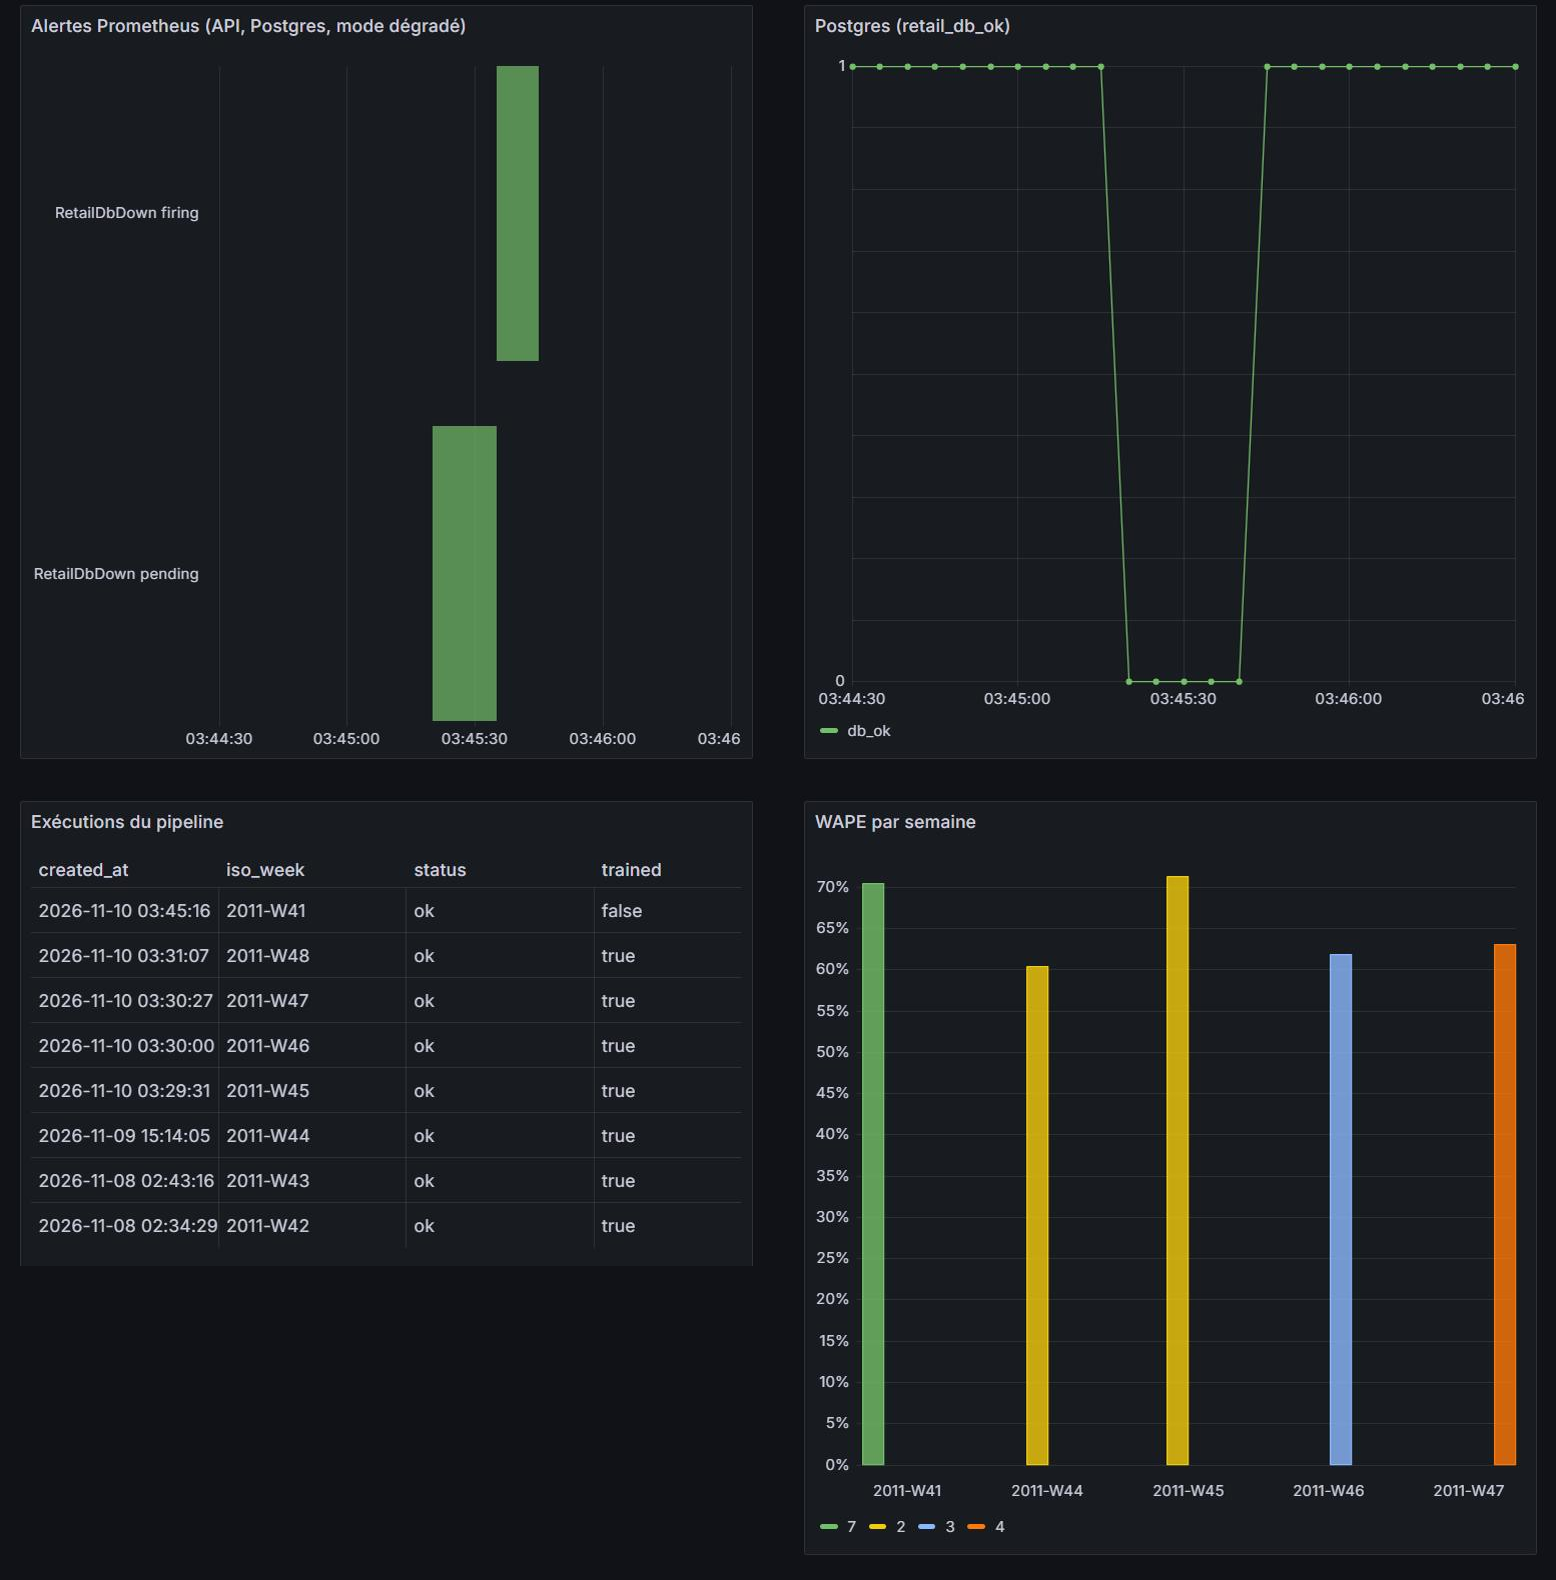

### 9. Démonstration nominale et incident contrôlé

La commande `retail demo` déroule toute la démonstration contre les services réels : vérifications, scénario nominal, lot invalide, coupure de PostgreSQL, retour arrière, puis restauration du champion d'origine dans un bloc `finally`.

In [ ]:
# Fichier : src/retail/demo.py (lignes 491 à 528)
def run_demo(*, skip_docker: bool = False, reset_cursor: bool = False) -> int:
    app = load_app_config()
    original = None
    rolled = None
    postgres_stopped = False
    try:
        if reset_cursor:
            reset_demo_cursor(app)
        health0 = step_checks(app, skip_docker=skip_docker)
        original = str(health0.get("_started_as") or health0.get("model_version"))
        served = str(health0.get("model_version"))
        nominal = step_nominal(app)
        step_invalid(app)
        if skip_docker:
            print("\n=== 3. Incident Postgres : ignore (--skip-docker) ===", flush=True)
        else:
            _banner("3. Incident Postgres coupe")
            sku = str((_get("/model").get("skus") or ["85123A"])[0])
            stop_postgres()
            postgres_stopped = True
            step_postgres_down(nominal["week_n1"], sku)
            step_restore_postgres()
            postgres_stopped = False
        rolled = step_rollback(app, served)
        step_bilan()
        print("\nDemo terminee.", flush=True)
        return 0
    finally:
        if postgres_stopped:
            try:
                step_restore_postgres()
            except Exception as extra:
                log.warning("Postgres non restaure", extra={"error": str(extra)})
        if original and rolled:
            try:
                restore_champion(app, original, rolled)
            except Exception as extra:
                log.warning("Champion non restaure", extra={"error": str(extra)})

Voici les deux incidents contrôlés : le lot invalide, qui doit être rejeté sans entraînement et générer une alerte, et la coupure de PostgreSQL, pendant laquelle `/predict` doit continuer à répondre et l'alerte `RetailDbDown` doit se déclencher.

In [ ]:
# Fichier : src/retail/demo.py (lignes 340 à 361)
def step_invalid(app) -> None:
    _banner("2. Incident lot invalide")
    run_invalid_demo(app)
    report = app.paths.reports_dir / "invalid_demo" / f"{INVALID_DEMO_WEEK}.json"
    _require(report.is_file(), f"rapport {report}")
    payload = json.loads(report.read_text(encoding="utf-8"))
    _require(payload.get("status") == "failed", f"status={payload.get('status')}")
    quality_copy = app.paths.reports_dir / "quality" / f"{INVALID_DEMO_WEEK}.json"
    _require(not quality_copy.exists(), "aucun rapport qualite 2099-W01 (pas d'entrainement)")
    emit_alert(
        app,
        {
            "kind": "quality",
            "week": INVALID_DEMO_WEEK,
            "message": "Lot invalide de demonstration rejete (porte qualite).",
        },
    )
    alerts = _get("/alerts")
    found = any(
        INVALID_DEMO_WEEK in json.dumps(item, default=str) for item in (alerts.get("alerts") or [])
    )
    _require(found, "GET /alerts contient le lot 2099-W01")


# Fichier : src/retail/demo.py (lignes 374 à 403)
def step_postgres_down(week: str, sku: str) -> None:
    grafana = os.environ.get("GRAFANA_PORT") or "3001"
    print(
        f"    Grafana http://127.0.0.1:{grafana} : retail_db_ok et ALERTS "
        f"{DB_DOWN_ALERT} (laisser Postgres coupe > 15 s)",
        flush=True,
    )
    predict = _post(
        "/predict",
        {"StockCode": sku, "week": week},
        timeout=30.0,
    )
    _require("prediction" in predict, "/predict repond toujours sans Postgres")
    health = _get("/health", timeout=15.0)
    _require(health.get("db_ok") is False, f"db_ok={health.get('db_ok')} (attendu false)")
    print(
        f"    API ok  version={health.get('model_version')}  db_ok=false  "
        "RetailApiDown ne s'applique pas",
        flush=True,
    )
    deadline = time.monotonic() + PROM_ALERT_WAIT_S
    while time.monotonic() < deadline:
        if prometheus_alert_firing(DB_DOWN_ALERT):
            _ok(f"Prometheus GET /api/v1/alerts : {DB_DOWN_ALERT} firing")
            return
        time.sleep(2)
    raise DemoError(
        f"{DB_DOWN_ALERT} n'est pas firing apres {int(PROM_ALERT_WAIT_S)} s "
        f"(GET {_prom_base()}/api/v1/alerts)."
    )

La démonstration exige l'API, PostgreSQL, MLflow, Prometheus et Docker ; elle n'est pas relancée dans ce notebook. La cellule suivante relit le journal réel de la démonstration du 10/11/2026 (`docs/captures/demo.txt`) et en affiche les lignes de contrôle, sans les lignes de log JSON.

In [18]:
demo = (ROOT / "docs" / "captures" / "demo.txt").read_text(encoding="utf-8", errors="replace").splitlines()
for line in demo:
    if line.strip() and not line.lstrip().startswith("{"):
        print(line)

    curseur remis a 2011-W40
=== 0. Verifications ===
OK  /health status=ok
OK  degraded=False
OK  model_version=7
OK  db_backend=postgresql (attendu postgresql)
OK  db_ok=True
    source=mlflow  version=7
    MLflow http://127.0.0.1:5001 : joignable
    chaine rollback deja en place (champion 7)
OK  champion disque C:\Users\KOURO\Desktop\Mini proejt mlde\models\champion\meta.json
OK  Toujours une seule version champion apres preparation du rollback.
    previous_champion=6
OK  Prometheus charge ['RetailApiDown', 'RetailDbDown', 'RetailDegraded', 'RetailHigh5xx'] (attendu RetailDbDown)
=== 1. Nominal (rejeu N -> predire N+1 -> rejeu N+1) ===
    curseur=2011-W40  N=2011-W40  N+1=2011-W41
OK  /predict/batch 2011-W41 : 50 predictions
OK  model_version=7 source=mlflow
    rejeu 2011-W41 (feedback auto, sans train)...
OK  GET /model production_wape=0.7046746623535111
    WAPE reelle=0.7047  n_skus=50
=== 2. Incident lot invalide ===
OK  rapport C:\Users\KOURO\Desktop\Mini proejt mlde\data\

**Interprétation :**

Les quatre scènes sont réussies. Dans le scénario nominal, l'API prédit les 50 produits de 2011-W41 avec la version 7, puis le rejeu de ce lot ferme les prédictions et donne une WAPE réelle de 0,7047. Le lot invalide 2099-W01 est rejeté avec le statut `failed`, aucun entraînement n'a lieu et l'alerte apparaît dans `GET /alerts`. Pendant la coupure de PostgreSQL, `/predict` répond toujours, `/health` indique `db_ok=False` et Prometheus déclenche `RetailDbDown` ; la base revient ensuite. Enfin, le retour arrière fait passer le champion de 7 à 6, puis la version 7 est restaurée.

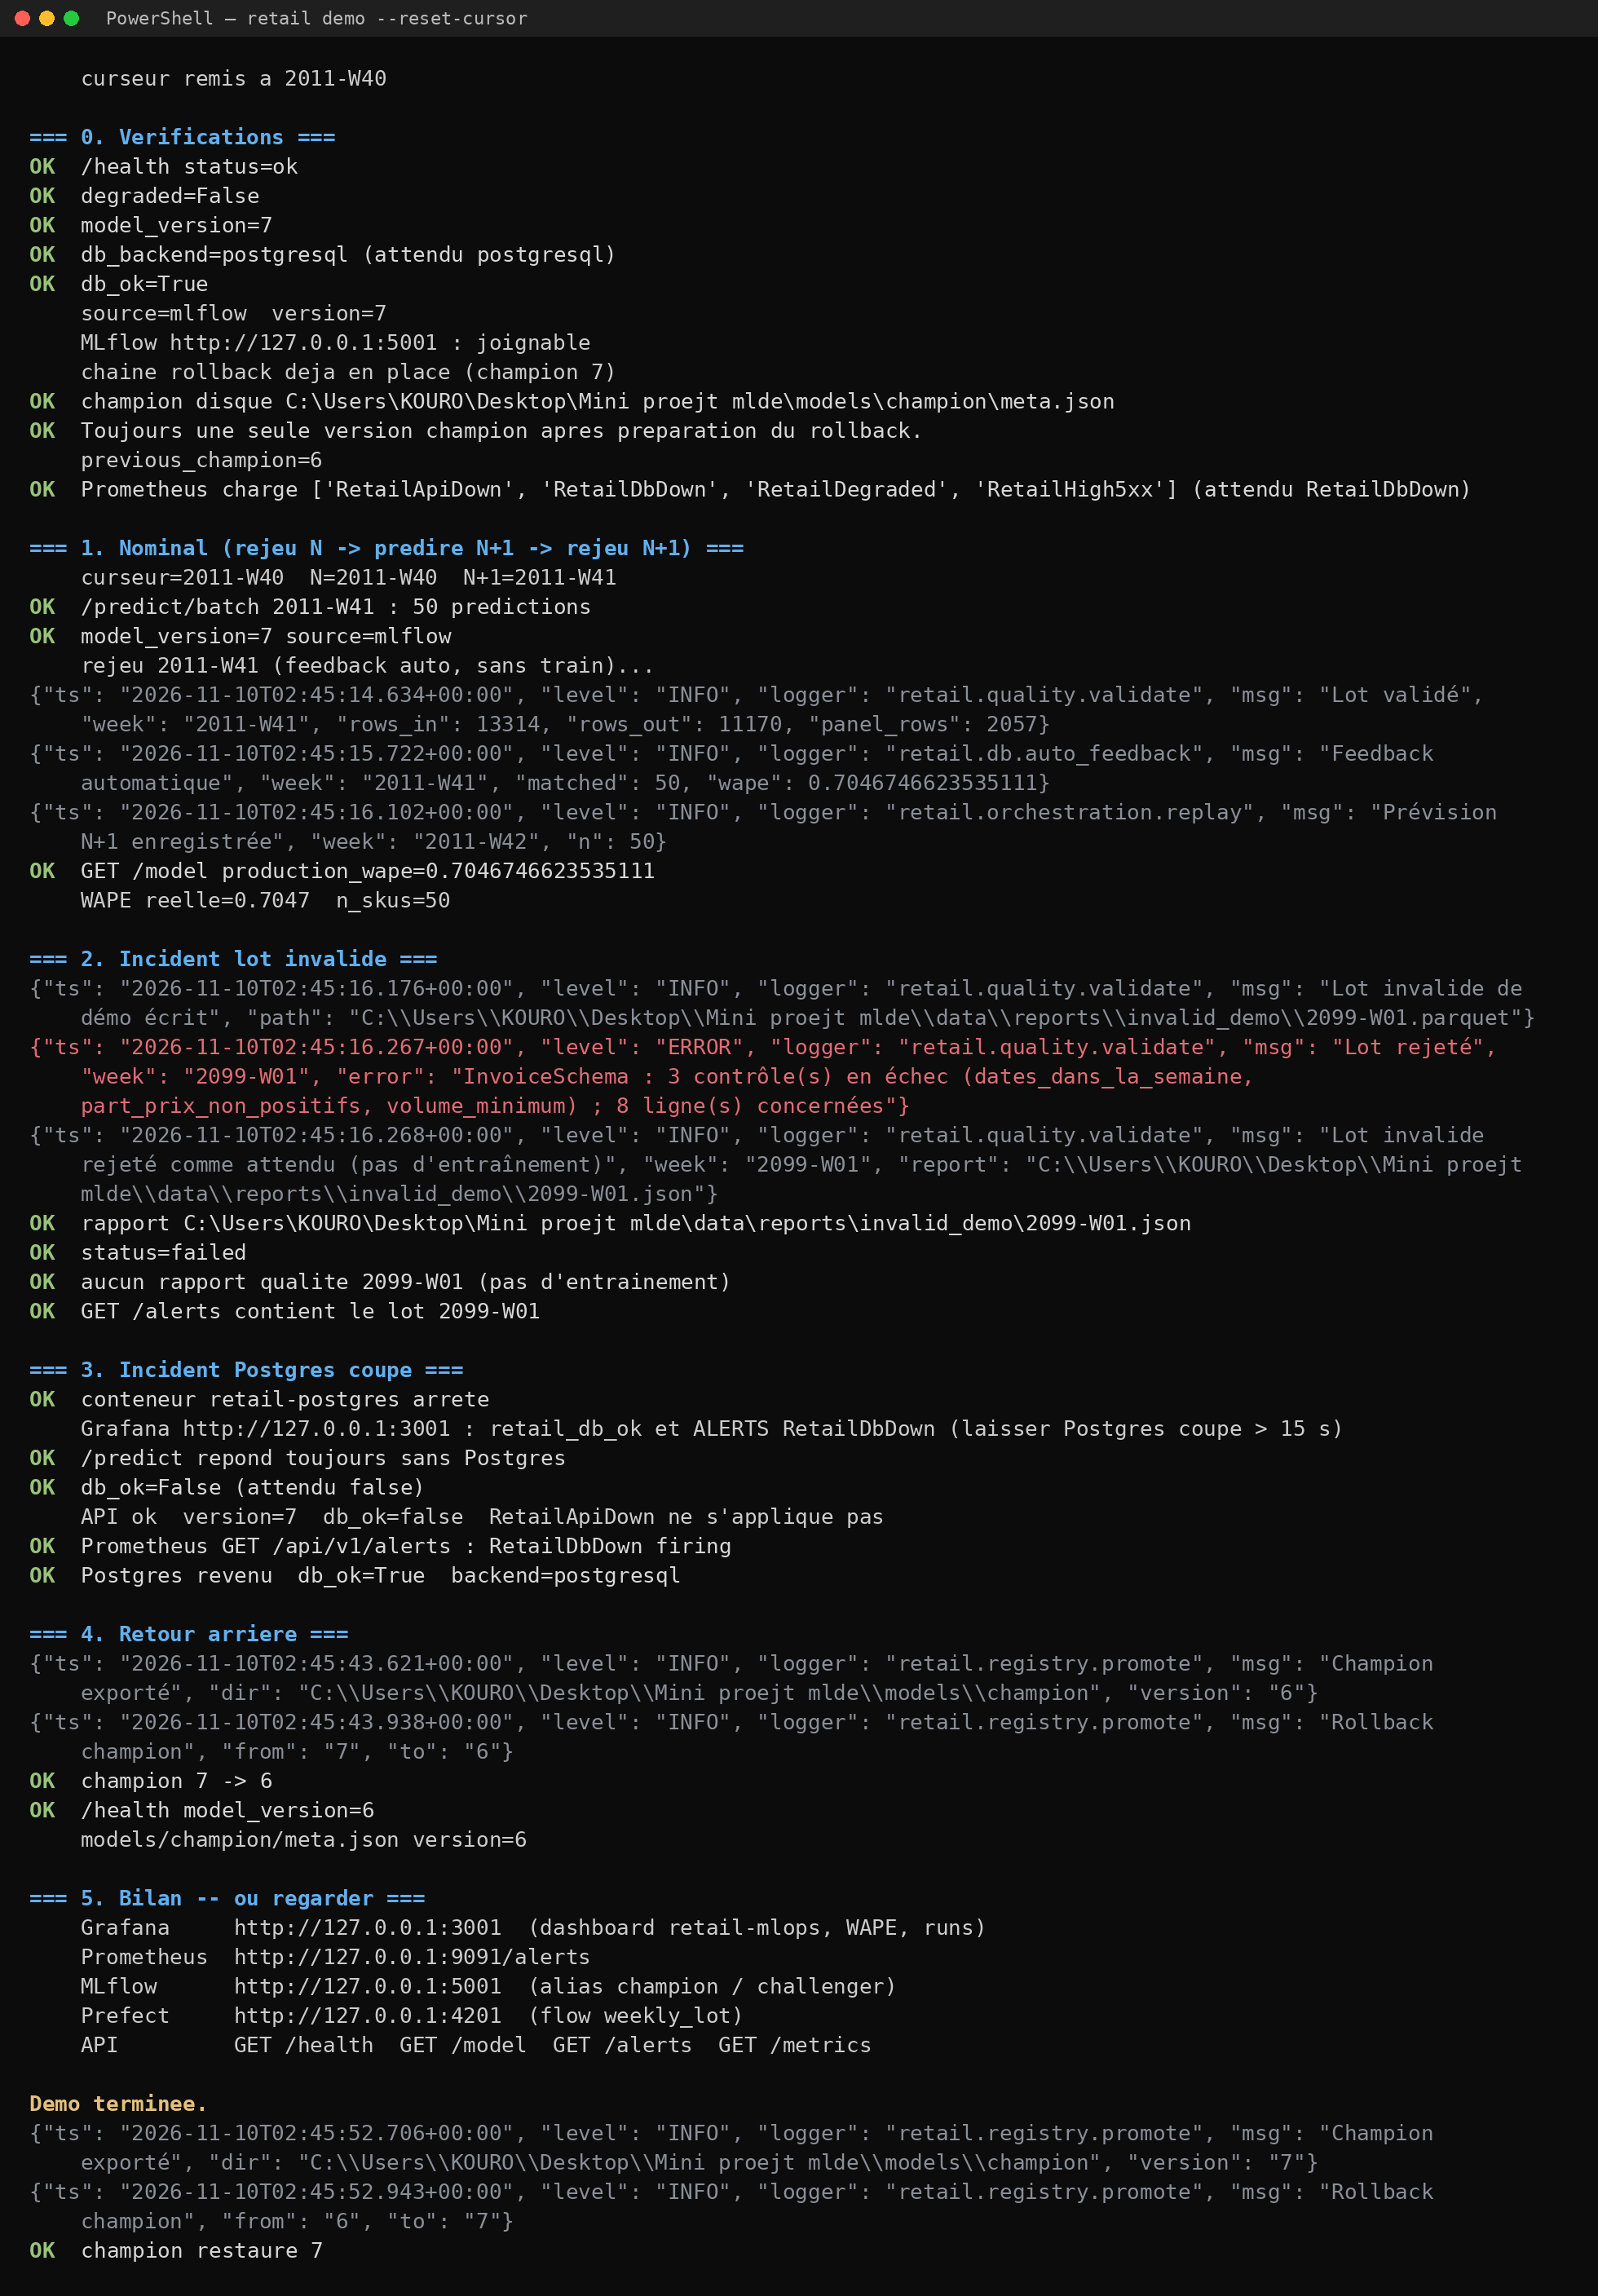

### 10. Limites et conclusion

**Limites connues** (reprises de `docs/SYNTHESE_OPS.md`) :

1. Tout le banc de mesure (API, Locust, PostgreSQL, Prometheus, Grafana) tourne sur un seul poste. En 4 workers et 2 vCPU, le passage à l'échelle se tasse sans que la cause soit départagée entre Locust, l'écriture SQL et le poste.
2. La capacité en 4 workers est seulement encadrée entre 60 et 82 req/s, faute de palier intermédiaire à 15 utilisateurs.
3. Le CPU de Locust n'a pas été mesuré correctement pendant la série 2.
4. La WAPE de production n'apparaît qu'après le rejeu du lot suivant, puisque la vérité terrain arrive avec lui.
5. Prefect n'est pas intégré à `retail demo` : son interface se lance à part.
6. La récupération des données dépend du site UCI, avec un repli par dépôt manuel de l'archive ; la séquence d'installation depuis un clone vide n'a pas été rejouée de bout en bout.

**Conclusion.** Le projet démontre une chaîne MLOps complète et reproductible autour d'un modèle volontairement simple. Les données sont ingérées avec une provenance vérifiée, contrôlées par des schémas bloquants, puis rejouées lot par lot par un orchestrateur qui relance les pannes techniques et alerte sur les échecs. Chaque modèle est tracé dans MLflow avec ses données, ses paramètres et ses métriques ; il n'est mis en service que s'il fait au moins aussi bien que le champion sur les mêmes semaines, et il peut être retiré par un retour arrière. L'API indique toujours la version qui répond, conserve chaque prédiction et mesure l'erreur réelle grâce aux feedbacks. Enfin, les tests de charge fondent une recommandation chiffrée, et le dashboard permet de suivre le service et de voir un incident au moment où il se produit.